# Практическая работа №2. Модельные методы рекомендательных систем на основе Марковских цепей

**Цель:** реализовать модельные рекомендательные методы на основе дискретной и непрерывной Марковских цепей, исследовать свойства цепей и применить их для рекомендаций; дополнительно — реализовать и обучить скрытую Марковскую модель.

**Предметная область — онлайн-кинотеатр** (та же, что в работе №1). Зритель смотрит и оценивает фильмы один за другим, и его интерес «переходит» между жанрами: после вечера фантастики он может остаться в фантастике, а может переключиться на комедию. Марковская цепь описывает именно эти переходы: **какой жанр зритель выберет следующим, зная, что он смотрит сейчас**. Это позволяет подстраивать главную страницу под текущий интерес зрителя, а не только под его вкус «в среднем».

**Отличие от работы №1.** Анамнестические методы хранят все оценки и при каждом запросе ищут похожих соседей. Модельный метод сначала по данным строит **модель с заранее заданной структурой** — набор состояний и вероятности переходов между ними, — а рекомендации выдаёт уже по модели.

**Начальные данные** (Примечание 1 методички): статистика уже сделанного пользователями выбора за период — оценки зрителей MovieLens за 2019–2023 годы. Порядок оценок во времени даёт последовательности выборов, из которых автоматически строятся матрица переходных вероятностей, матрица интенсивностей и вектор начальных состояний.

План работы:
1. Состояния цепи: жанровые группы фильмов.
2. **Дискретная цепь**: матрица переходных вероятностей, вектор начальных состояний, состояние на шаге $n$, свойства (переходы, достижимость, стационарность).
3. **Непрерывная цепь**: матрица интенсивностей (плотностей вероятностей переходов), состояние в момент времени $t$, стационарное распределение.
4. Применение цепей: прогноз группы следующего фильма и следующей сессии, топ-N рекомендации фильмов.
5. Дополнительно: **скрытая Марковская модель** — алгоритмы прямого-обратного хода, Витерби и Баума — Велша.

В ноутбуке приведены только итоговые модели. Их параметры (степень сглаживания персональной цепи, число скрытых состояний, параметры цепи на уровне фильмов) выбраны на этапе исследования по валидационной выборке — последним 20 % оценок обучающей части каждого зрителя — и здесь используются как готовые значения.

In [107]:
import os
import time
from functools import wraps
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
from scipy.linalg import expm
from scipy.stats import chi2_contingency

import ml_common as mc

Оценка используемых ресурсов

In [108]:
def measure_resources(func):
    @wraps(func)
    def wrapper(*args, **kwargs):
        process = psutil.Process(os.getpid())

        start_time = time.time()
        start_memory = process.memory_info().rss / 1024**2  # MB
        result = func(*args, **kwargs)
        end_time = time.time()
        end_memory = process.memory_info().rss / 1024**2

        print(f"Время: {end_time - start_time:.2f}с")
        print(f"Память: +{end_memory - start_memory:.1f} MB (макс: {end_memory:.1f} MB)")

        return result
    return wrapper

Единый стиль графиков. Каждое состояние цепи (жанровая группа) на всех графиках имеет один и тот же цвет.

In [109]:
MAIN_COLOR = "#3987e5"
PALETTE = ["#3987e5", "#d95926", "#199e70", "#c98500", "#d55181", "#008300", "#9085e9", "#e66767"]
MARKERS = ["o", "s", "^", "D", "v", "P", "X", "*"]

plt.rcParams.update({
    "figure.dpi": 100,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 2,
})


def show_matrix(ax, matrix, labels_rows, labels_cols, title, fmt="{:.2f}", cmap="Blues", vmin=None, vmax=None):
    # Тепловая карта матрицы с подписями значений в клетках
    image = ax.imshow(matrix, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(labels_cols)))
    ax.set_xticklabels(labels_cols, rotation=35, ha="right")
    ax.set_yticks(range(len(labels_rows)))
    ax.set_yticklabels(labels_rows)
    ax.grid(False)
    threshold = np.nanmax(np.abs(matrix)) * 0.6
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            value = matrix[i, j]
            color = "white" if abs(value) > threshold else "black"
            ax.text(j, i, fmt.format(value), ha="center", va="center", fontsize=8, color=color)
    ax.set_title(title)
    return image

# Загрузка данных

Используется тот же срез MovieLens 32M и то же временное разбиение, что в работе №1: `train` — первые 80 % оценок каждого пользователя по времени, `test` — последние 20 %. Модели строятся по `train`, качество проверяется на `test`.

In [110]:
data = mc.load_slice()
train_full = data["train"]
test = data["test"]
movies = data["movies"]

print(f"Обучающая выборка: {len(train_full):,} оценок, тестовая: {len(test):,}")
print(f"Пользователей: {train_full['userId'].nunique():,}, фильмов: {len(movies):,}")

Обучающая выборка: 140,054 оценок, тестовая: 35,018
Пользователей: 1,988, фильмов: 2,191


# Состояния цепи: жанровые группы

Марковская цепь описывает систему, которая в каждый момент находится в одном из конечного числа **состояний** и случайно переходит между ними. Нужно решить, что считать состоянием зрителя.

Состояние — **жанровая группа фильма, который зритель смотрит сейчас**. Почему не отдельный фильм и не отдельный жанр:
- **фильмов** больше двух тысяч: матрица переходов «фильм → фильм» содержала бы 4.8 млн чисел, и почти все переходы встречались бы по одному разу или ни разу. Такую матрицу нельзя надёжно оценить, а граф цепи — нарисовать;
- **жанров** в MovieLens 19, и у фильма их обычно несколько (например, `Action|Adventure|Sci-Fi`). Состояние же должно быть одно. Кроме того, редкие жанры (Film-Noir, Musical, Western) дали бы строки матрицы, оценённые по единицам переходов.

Поэтому жанры объединены в **6 групп** по смыслу (словарь `mc.GENRE_GROUPS`). Фильм относится к **первой по приоритету** группе, в которую входит хотя бы один его жанр. Приоритет — от узких групп к широким: семейное → фантастика → боевик → триллер → комедия → драма. Так фильм `Action|Adventure|Sci-Fi` попадает в «Фантастику», а не в «Боевик» — фантастический элемент определяет его сильнее. Драма — самый частый «сопутствующий» жанр (`Crime|Drama|Thriller`), поэтому она последняя: в «Драму» попадают фильмы, у которых нет более специфичного жанра. Жанр IMAX — формат показа, он не учитывается.

In [111]:
STATES = mc.GROUP_NAMES
N_STATES = len(STATES)
STATE_COLORS = {name: PALETTE[i] for i, name in enumerate(STATES)}

movies["state"] = movies["genre_list"].apply(mc.genre_group)
state_of = movies.set_index("movieId")["state"]

for index, (name, genres) in enumerate(mc.GENRE_GROUPS.items()):
    print(f"{index}  {name:<11}: {', '.join(genres)}")

0  Семейное   : Animation, Children
1  Фантастика : Sci-Fi, Fantasy
2  Боевик     : Action, Adventure, War, Western
3  Триллер    : Thriller, Horror, Crime, Mystery, Film-Noir
4  Комедия    : Comedy, Musical
5  Драма      : Drama, Romance, Documentary


Сколько фильмов и оценок приходится на каждое состояние. Для надёжной оценки переходов каждое состояние должно встречаться достаточно часто.

 Состояние  Фильмов  Доля фильмов  Доля оценок
  Семейное      255         0.116        0.106
Фантастика      418         0.191        0.347
    Боевик      361         0.165        0.168
   Триллер      456         0.208        0.168
   Комедия      320         0.146        0.097
     Драма      381         0.174        0.115


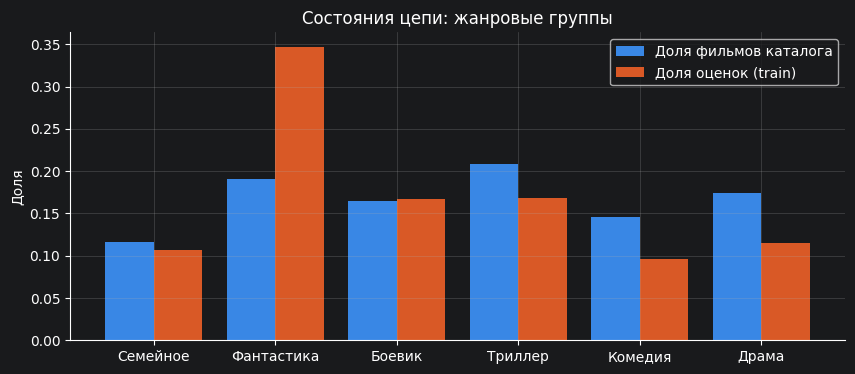

In [112]:
movie_share = movies["state"].value_counts(normalize=True).sort_index()
rating_share = train_full["movieId"].map(state_of).value_counts(normalize=True).sort_index()
state_table = pd.DataFrame({"Состояние": STATES,
                            "Фильмов": movies["state"].value_counts().sort_index().to_numpy(),
                            "Доля фильмов": movie_share.to_numpy(),
                            "Доля оценок": rating_share.to_numpy()})
print(state_table.round(3).to_string(index=False))

x = np.arange(N_STATES)
plt.figure(figsize=(10, 4))
plt.bar(x - 0.2, movie_share, width=0.4, color=PALETTE[0], label="Доля фильмов каталога")
plt.bar(x + 0.2, rating_share, width=0.4, color=PALETTE[1], label="Доля оценок (train)")
plt.xticks(x, STATES)
plt.ylabel("Доля")
plt.title("Состояния цепи: жанровые группы")
plt.legend()
plt.show()

Примеры отнесения популярных фильмов к группам:

In [113]:
popular = train_full["movieId"].value_counts().index[:12]
examples = movies.set_index("movieId").loc[popular, ["title", "genre_list", "state"]]
for movie_id, row in examples.iterrows():
    print(f"{STATES[row['state']]:<11} <- {row['title']}  [{', '.join(row['genre_list'])}]")

Фантастика  <- Inception (2010)  [Action, Crime, Drama, Mystery, Sci-Fi, Thriller, IMAX]
Фантастика  <- Interstellar (2014)  [Sci-Fi, IMAX]
Фантастика  <- The Martian (2015)  [Adventure, Drama, Sci-Fi]
Фантастика  <- Guardians of the Galaxy (2014)  [Action, Adventure, Sci-Fi]
Боевик      <- Django Unchained (2012)  [Action, Drama, Western]
Триллер     <- Wolf of Wall Street, The (2013)  [Comedy, Crime, Drama]
Фантастика  <- Avengers: Infinity War - Part II (2019)  [Action, Adventure, Sci-Fi]
Фантастика  <- Arrival (2016)  [Sci-Fi]
Фантастика  <- Deadpool (2016)  [Action, Adventure, Comedy, Sci-Fi]
Боевик      <- Dark Knight Rises, The (2012)  [Action, Adventure, Crime, IMAX]
Фантастика  <- Avengers: Infinity War - Part I (2018)  [Action, Adventure, Sci-Fi]
Триллер     <- Joker (2019)  [Crime, Drama, Thriller]


# Последовательности состояний

Для каждого пользователя оценки упорядочиваются по времени, и каждой оценке ставится в соответствие состояние — группа фильма. Получается последовательность вида «Фантастика → Фантастика → Боевик → Комедия → …».

В ноутбуке подготовки данных выяснилось, что зрители оценивают фильмы **пачками**: 68 % соседних оценок разделены меньше чем минутой. Поэтому строятся последовательности двух уровней:
- **по оценкам** — каждая оценка — шаг цепи. Шагов много, но порядок оценок внутри одного захода на сайт отчасти отражает то, как сайт показывал фильмы;
- **по сессиям** — шаг цепи — сессия (заход на сайт, граница — пауза больше часа). Состояние сессии — группа, которая в ней преобладает (при равенстве — первая по приоритету). Шагов меньше, но каждый шаг — осознанное возвращение зрителя.

Сессии также дают время: момент начала каждой сессии используется в непрерывной цепи.

In [114]:
SESSION_GAP = 3600   # граница сессии - пауза больше часа (как в ноутбуке подготовки данных)
SECONDS_PER_DAY = 86400


def add_states(ratings):
    seq = mc.assign_sessions(ratings, gap_seconds=SESSION_GAP)   # сортировка: пользователь, время
    seq["state"] = seq["movieId"].map(state_of).to_numpy()
    return seq


def rating_transitions(seq):
    # Пары соседних оценок одного пользователя: (из состояния, в состояние)
    users = seq["userId"].to_numpy()
    states = seq["state"].to_numpy()
    same_user = users[1:] == users[:-1]
    return states[:-1][same_user], states[1:][same_user]


def session_table(seq):
    # Одна строка на сессию: преобладающее состояние, время начала и конца, доли групп в сессии
    counts = seq.groupby(["userId", "session", "state"]).size().rename("n").reset_index()
    counts = counts.sort_values(["userId", "session", "n", "state"], ascending=[True, True, False, True])
    dominant = counts.drop_duplicates(["userId", "session"])[["userId", "session", "state"]]
    times = (seq.groupby(["userId", "session"])["timestamp"]
             .agg(start="min", end="max", size="size").reset_index())
    sessions = dominant.merge(times, on=["userId", "session"]).sort_values(["userId", "start"])
    shares = (counts.pivot_table(index=["userId", "session"], columns="state", values="n", fill_value=0)
              .reindex(columns=range(N_STATES), fill_value=0))
    shares = shares.div(shares.sum(axis=1), axis=0)
    return sessions.reset_index(drop=True), shares


seq_full = add_states(train_full)
sessions_full, session_shares_full = session_table(seq_full)

print(f"Оценок: {len(seq_full):,}, сессий: {len(sessions_full):,}")
print(f"Переходов между оценками: {len(rating_transitions(seq_full)[0]):,}")
print(f"Переходов между сессиями: {(sessions_full['userId'].diff() == 0).sum():,}")

Оценок: 140,054, сессий: 17,483
Переходов между оценками: 138,066
Переходов между сессиями: 15,495


Пример последовательности одного активного пользователя (первые 40 оценок). Вертикальная черта `|` — граница сессий.

In [115]:
example_user = sessions_full["userId"].value_counts().index[10]
example_seq = seq_full[seq_full["userId"] == example_user].head(40)
parts = []
for session, group in example_seq.groupby("session", sort=False):
    parts.append(" → ".join(STATES[s] for s in group["state"]))
print(f"Пользователь {example_user}:")
print("\n | ".join(parts))

Пользователь 81271:
Драма
 | Комедия
 | Триллер
 | Драма
 | Триллер
 | Драма
 | Комедия
 | Семейное
 | Фантастика
 | Боевик
 | Триллер
 | Семейное
 | Драма
 | Фантастика
 | Семейное
 | Триллер
 | Фантастика
 | Фантастика
 | Комедия
 | Боевик
 | Фантастика
 | Семейное
 | Комедия
 | Триллер
 | Драма → Драма
 | Фантастика
 | Комедия
 | Фантастика
 | Триллер
 | Боевик
 | Комедия
 | Фантастика
 | Драма
 | Комедия
 | Семейное
 | Комедия
 | Семейное
 | Триллер
 | Боевик


Уже на одном пользователе видна главная особенность: подряд часто идут фильмы одной группы. Это и есть то, что должна уловить цепь, — вероятность остаться в том же состоянии.

# Дискретная Марковская цепь

## Матрица переходных вероятностей

Дискретная цепь меняет состояние в моменты $n = 0, 1, 2, \dots$ (шаги). **Марковское свойство**: вероятность следующего состояния зависит только от текущего состояния, а не от всей предыстории:
$$P(X_{n+1} = j \mid X_n = i, X_{n-1}, \dots, X_0) = P(X_{n+1} = j \mid X_n = i) = p_{ij}.$$

Матрица $P = (p_{ij})$ — **матрица переходных вероятностей**: строка $i$ — распределение следующего состояния, если сейчас цепь в состоянии $i$; сумма каждой строки равна 1. Цепь **однородна**: $p_{ij}$ не зависят от номера шага.

Матрица строится автоматически по начальным данным. Оценка максимального правдоподобия — доля переходов:
$$\hat p_{ij} = \frac{n_{ij}}{\sum_k n_{ik}},$$
где $n_{ij}$ — сколько раз во всех последовательностях за состоянием $i$ сразу следовало состояние $j$. Переходов больше ста тысяч, поэтому каждая из 36 клеток оценена по сотням и тысячам случаев — сглаживание не требуется.

Минимальное число переходов в клетке: 1216


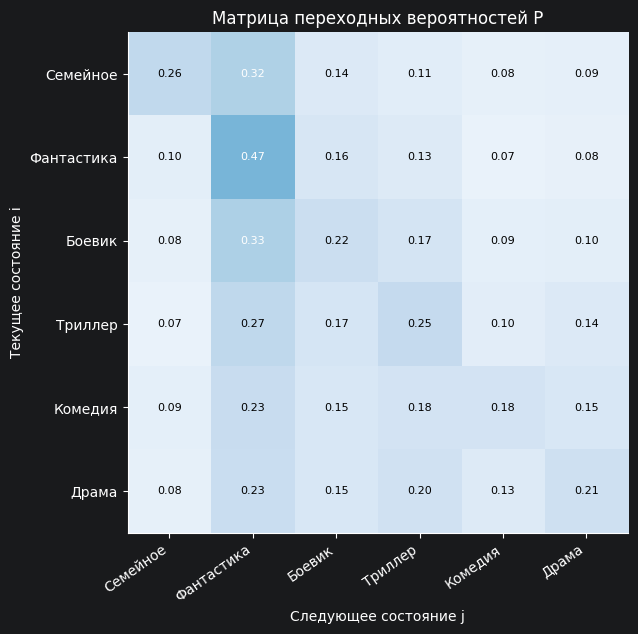

In [116]:
def count_matrix(from_states, to_states):
    counts = np.zeros((N_STATES, N_STATES))
    np.add.at(counts, (from_states, to_states), 1)
    return counts


def transition_matrix(counts, alpha=0.0):
    # alpha - аддитивное сглаживание (на случай нулевых строк)
    counts = counts + alpha
    return counts / counts.sum(axis=1, keepdims=True)


from_states, to_states = rating_transitions(seq_full)
N_ratings = count_matrix(from_states, to_states)
P_ratings = transition_matrix(N_ratings)
print("Минимальное число переходов в клетке:", int(N_ratings.min()))

fig, ax = plt.subplots(figsize=(8.5, 6.5))
show_matrix(ax, P_ratings, STATES, STATES, "Матрица переходных вероятностей P", vmin=0, vmax=1)
ax.set_xlabel("Следующее состояние j")
ax.set_ylabel("Текущее состояние i")
plt.show()

Как читать матрицу: строка — где зритель сейчас, столбец — куда он перейдёт на следующем шаге. Диагональ — вероятность **остаться** в той же группе. Если бы выбор следующего фильма не зависел от текущего, все строки были бы одинаковы и равны общим долям групп; отличие строк друг от друга — это и есть марковская зависимость.

Насколько диагональ выше, чем при независимом выборе, показывает сравнение $p_{ii}$ с долей состояния $\pi_i$ среди всех оценок:

In [117]:
state_freq = np.bincount(seq_full["state"], minlength=N_STATES) / len(seq_full)
stickiness = pd.DataFrame({
    "Доля состояния": state_freq,
    "p_ii": np.diag(P_ratings),
}, index=STATES)
stickiness["Во сколько раз выше доли"] = stickiness["p_ii"] / stickiness["Доля состояния"]
print(stickiness.round(3).to_string())

            Доля состояния   p_ii  Во сколько раз выше доли
Семейное             0.106  0.262                     2.466
Фантастика           0.347  0.467                     1.346
Боевик               0.168  0.224                     1.337
Триллер              0.168  0.252                     1.504
Комедия              0.097  0.183                     1.896
Драма                0.115  0.205                     1.786


Внутри сессии и между сессиями

Высокая диагональ при переходах между оценками может объясняться не вкусом, а устройством сайта: в одном заходе зритель часто оценивает фильмы из одной подборки. Проверим: разделим переходы между соседними оценками на те, что **внутри сессии**, и те, что **через границу сессий**, и сравним вероятность остаться в той же группе.

In [118]:
users = seq_full["userId"].to_numpy()
sessions_arr = seq_full["session"].to_numpy()
states_arr = seq_full["state"].to_numpy()
same_user = users[1:] == users[:-1]
inside = same_user & (sessions_arr[1:] == sessions_arr[:-1])
across = same_user & (sessions_arr[1:] != sessions_arr[:-1])

P_inside = transition_matrix(count_matrix(states_arr[:-1][inside], states_arr[1:][inside]))
P_across = transition_matrix(count_matrix(states_arr[:-1][across], states_arr[1:][across]))
print(f"Переходов внутри сессий: {inside.sum():,}, через границу: {across.sum():,}")
print(pd.DataFrame({"p_ii внутри сессии": np.diag(P_inside),
                    "p_ii через границу": np.diag(P_across),
                    "Доля состояния": state_freq}, index=STATES).round(3).to_string())

Переходов внутри сессий: 122,571, через границу: 15,495
            p_ii внутри сессии  p_ii через границу  Доля состояния
Семейное                 0.270               0.194           0.106
Фантастика               0.481               0.323           0.347
Боевик                   0.225               0.218           0.168
Триллер                  0.250               0.268           0.168
Комедия                  0.184               0.175           0.097
Драма                    0.205               0.207           0.115


Если $p_{ii}$ через границу сессий заметно меньше, чем внутри, но всё ещё выше доли состояния, значит, часть «липкости» объясняется подборками сайта, но и между заходами зритель склонен возвращаться к той же группе — это уже свойство вкуса.

## Проверка марковской зависимости

Формальная проверка: нулевая гипотеза — следующее состояние **не зависит** от текущего (строки матрицы одинаковы). Проверяется критерием хи-квадрат по таблице сопряжённости $n_{ij}$. Если гипотеза отвергается, у цепи есть «память» длиной хотя бы в один шаг, и модель имеет смысл.

## Проверка марковской зависимости

Формальная проверка: нулевая гипотеза — следующее состояние **не зависит** от текущего (строки матрицы одинаковы). Проверяется критерием хи-квадрат по таблице сопряжённости $n_{ij}$. Если гипотеза отвергается, у цепи есть «память» длиной хотя бы в один шаг, и модель имеет смысл.

In [119]:
chi2, p_value, dof, expected = chi2_contingency(N_ratings)
# V Крамера - сила зависимости от 0 (нет) до 1 (полная), не зависит от объёма выборки
cramers_v = np.sqrt(chi2 / (N_ratings.sum() * (N_STATES - 1)))
print(f"chi2 = {chi2:,.0f}, df = {dof}, p-value = {p_value:.2g}, V Крамера = {cramers_v:.3f}")

chi2 = 13,560, df = 25, p-value = 0, V Крамера = 0.140


При сотне тысяч переходов критерий отвергнет независимость даже при очень слабой связи, поэтому важнее **V Крамера** — мера силы связи, не зависящая от объёма выборки: значения около 0.1 считаются слабой связью, около 0.3 — умеренной, от 0.5 — сильной.

## Вектор начальных состояний и состояние на шаге $n$

**Вектор начальных состояний** $\pi^{(0)}$ — распределение состояния в начальный момент. Для системы в целом это распределение групп **первого** фильма, который оценили пользователи: с чего зрители начинают знакомство с кинотеатром.

Состояние системы на шаге $n$ — распределение вероятностей $\pi^{(n)}$ — вычисляется по уравнению Колмогорова — Чепмена:
$$\pi^{(n)} = \pi^{(n-1)} P = \pi^{(0)} P^n.$$
Матрица $P^n$ — матрица переходных вероятностей **за $n$ шагов**: элемент $(P^n)_{ij}$ — вероятность оказаться в $j$ через $n$ шагов, начав в $i$.

In [120]:
first_states = seq_full.groupby("userId")["state"].first()
pi0 = np.bincount(first_states, minlength=N_STATES) / len(first_states)


def state_at_step(pi_start, P, n):
    return pi_start @ np.linalg.matrix_power(P, n)


steps = list(range(0, 11)) + [20, 50]
state_by_step = pd.DataFrame([state_at_step(pi0, P_ratings, n) for n in steps],
                             index=pd.Index(steps, name="Шаг n"), columns=STATES)
print("Состояние системы на шаге n (старт - распределение первых фильмов пользователей):")
print(state_by_step.round(3).to_string())

Состояние системы на шаге n (старт - распределение первых фильмов пользователей):
       Семейное  Фантастика  Боевик  Триллер  Комедия  Драма
Шаг n                                                       
0         0.097       0.449   0.113    0.132    0.087  0.121
1         0.107       0.362   0.165    0.162    0.093  0.112
2         0.107       0.348   0.168    0.167    0.096  0.114
3         0.106       0.346   0.168    0.168    0.097  0.115
4         0.106       0.345   0.168    0.168    0.097  0.115
5         0.106       0.345   0.168    0.168    0.097  0.115
6         0.106       0.345   0.168    0.168    0.097  0.115
7         0.106       0.345   0.168    0.168    0.097  0.115
8         0.106       0.345   0.168    0.168    0.097  0.115
9         0.106       0.345   0.168    0.168    0.097  0.115
10        0.106       0.345   0.168    0.168    0.097  0.115
20        0.106       0.345   0.168    0.168    0.097  0.115
50        0.106       0.345   0.168    0.168    0.097  0.115


Так выглядит эволюция распределения, если зритель **точно** находится в одном состоянии (вектор начальных состояний — единица в этом состоянии). Слева — старт в «Семейном», справа — старт в «Драме».

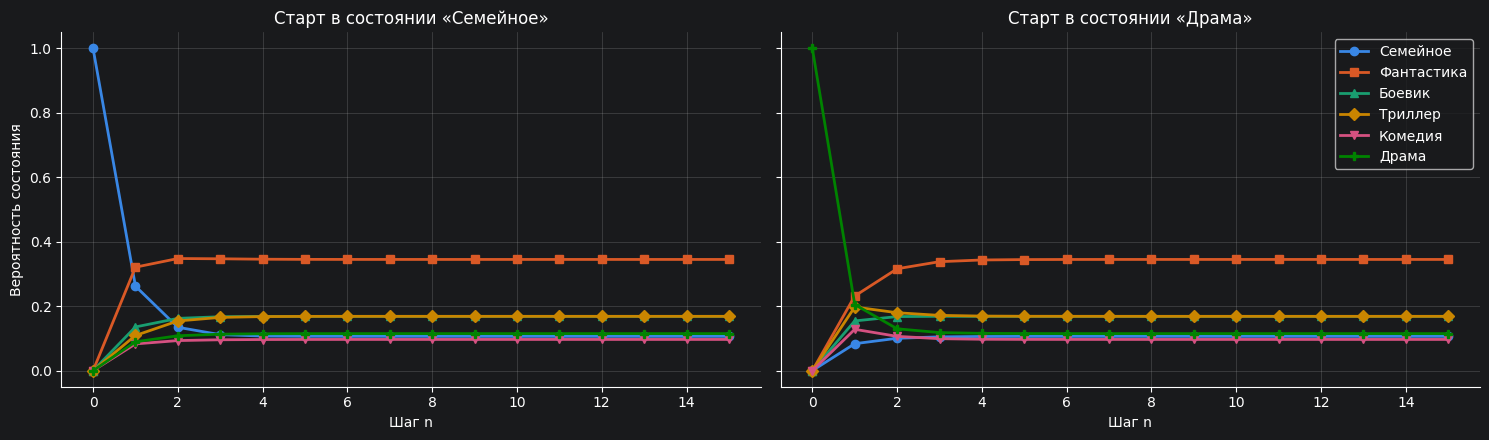

In [121]:
n_range = np.arange(0, 16)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, start in zip(axes, [0, N_STATES - 1]):
    pi_start = np.eye(N_STATES)[start]
    trajectory = np.array([state_at_step(pi_start, P_ratings, n) for n in n_range])
    for j, name in enumerate(STATES):
        ax.plot(n_range, trajectory[:, j], marker=MARKERS[j], color=PALETTE[j], label=name)
    ax.set_title(f"Старт в состоянии «{STATES[start]}»")
    ax.set_xlabel("Шаг n")
axes[0].set_ylabel("Вероятность состояния")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

С ростом $n$ кривые выходят на горизонтальные уровни, причём одинаковые при любом старте: цепь «забывает», откуда начала. Эти уровни — **стационарное распределение**.

## Свойства цепи

**Переходы и достижимость.** Состояние $j$ достижимо из $i$, если $(P^n)_{ij} > 0$ при некотором $n$. Цепь **неприводима**, если все состояния достижимы друг из друга, и **апериодична**, если возврат в состояние возможен за любое достаточно большое число шагов (достаточно, чтобы $p_{ii} > 0$). Неприводимая апериодичная цепь с конечным числом состояний — **регулярная** (эргодическая): у неё существует единственное стационарное распределение, и $\pi^{(n)}$ сходится к нему из любого начального вектора.

**Стационарное распределение** $\pi$ — решение системы
$$\pi P = \pi, \qquad \sum_i \pi_i = 1,$$
то есть левый собственный вектор $P$ с собственным значением 1. Оно показывает долю шагов, которую цепь в долгосрочной перспективе проводит в каждом состоянии.

**Скорость сходимости** определяется вторым по модулю собственным значением $|\lambda_2|$: расстояние до стационарного распределения убывает примерно как $|\lambda_2|^n$.

**Характеристики времени:**
- среднее число шагов подряд в состоянии $i$ (время пребывания): $1 / (1 - p_{ii})$;
- среднее время возвращения в $i$: $1 / \pi_i$;
- среднее время первого достижения $j$ из $i$: $m_{ij}$, вычисляется через фундаментальную матрицу $Z = (I - P + \mathbf{1}\pi)^{-1}$: $m_{ij} = (z_{jj} - z_{ij}) / \pi_j$.

In [122]:
def stationary_distribution(P):
    # Решаем pi (P - I) = 0 вместе с условием нормировки sum(pi) = 1 методом наименьших квадратов
    n = P.shape[0]
    A = np.vstack([(P - np.eye(n)).T, np.ones(n)])
    b = np.r_[np.zeros(n), 1.0]
    return np.linalg.lstsq(A, b, rcond=None)[0]


def chain_properties(P, name):
    n = P.shape[0]
    reach = np.linalg.matrix_power(np.eye(n) + P, n - 1) > 0
    regular_power = next((k for k in range(1, 50) if (np.linalg.matrix_power(P, k) > 0).all()), None)
    eigenvalues = np.sort(np.abs(np.linalg.eigvals(P)))[::-1]
    pi = stationary_distribution(P)

    # Число шагов до сходимости: полуразность L1 (расстояние полной вариации) < 0.01 из любого старта
    steps_to_mix = next(k for k in range(1, 1000)
                        if 0.5 * np.abs(np.linalg.matrix_power(P, k) - pi).sum(axis=1).max() < 0.01)

    print(f"=== {name} ===")
    print(f"Неприводима (все состояния достижимы друг из друга): {reach.all()}")
    print(f"Апериодична (есть p_ii > 0): {(np.diag(P) > 0).any()}")
    print(f"Регулярна: все элементы P^k > 0 начиная с k = {regular_power}")
    print(f"Модули собственных значений: {np.round(eigenvalues, 3)}")
    print(f"|lambda_2| = {eigenvalues[1]:.3f}; до стационарного распределения (с точностью 0.01): {steps_to_mix} шагов")
    print(f"Проверка pi P = pi: max|pi P - pi| = {np.abs(pi @ P - pi).max():.1e}")
    return pi, steps_to_mix


def first_passage_times(P, pi):
    n = P.shape[0]
    Z = np.linalg.inv(np.eye(n) - P + np.outer(np.ones(n), pi))
    M = (np.diag(Z)[None, :] - Z) / pi[None, :]
    M[np.diag_indices(n)] = 1 / pi
    return M


pi_ratings, mix_ratings = chain_properties(P_ratings, "Дискретная цепь")

time_table = pd.DataFrame({
    "pi (оценки)": pi_ratings,
    "Доля оценок": state_freq,
    "Пребывание, шагов": 1 / (1 - np.diag(P_ratings)),
    "Возвращение, шагов": 1 / pi_ratings,
}, index=STATES)
print()
print(time_table.round(3).to_string())

=== Дискретная цепь ===
Неприводима (все состояния достижимы друг из друга): True
Апериодична (есть p_ii > 0): True
Регулярна: все элементы P^k > 0 начиная с k = 1
Модули собственных значений: [1.    0.24  0.17  0.078 0.06  0.046]
|lambda_2| = 0.240; до стационарного распределения (с точностью 0.01): 3 шагов
Проверка pi P = pi: max|pi P - pi| = 2.8e-16

            pi (оценки)  Доля оценок  Пребывание, шагов  Возвращение, шагов
Семейное          0.106        0.106              1.355               9.402
Фантастика        0.345        0.347              1.876               2.898
Боевик            0.168        0.168              1.289               5.937
Триллер           0.168        0.168              1.338               5.936
Комедия           0.097        0.097              1.224              10.333
Драма             0.115        0.115              1.258               8.704


Стационарное распределение цепи по оценкам должно почти совпадать с долями оценок в данных — это проверка корректности расчёта: на длинных последовательностях доля шагов в состоянии и есть стационарная вероятность.

Матрица средних времён первого достижения (в шагах): сколько оценок в среднем пройдёт, прежде чем зритель из группы $i$ впервые доберётся до группы $j$. На диагонали — среднее время возвращения.

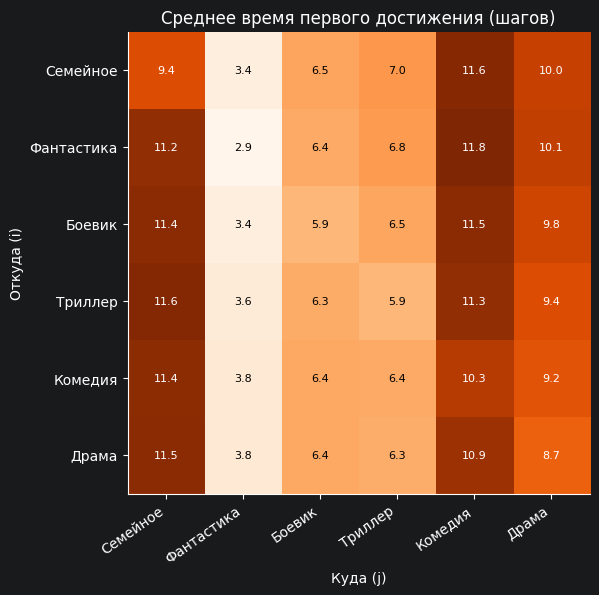

In [123]:
passage = first_passage_times(P_ratings, pi_ratings)
fig, ax = plt.subplots(figsize=(8, 6))
show_matrix(ax, passage, STATES, STATES, "Среднее время первого достижения (шагов)", fmt="{:.1f}", cmap="Oranges")
ax.set_xlabel("Куда (j)")
ax.set_ylabel("Откуда (i)")
plt.show()

Переходы цепи для графа модели

Граф цепи (вершины — состояния, дуги — переходы с вероятностями) построен отдельно и приложен к отчёту. Для его построения ниже выводятся все переходы цепи по оценкам: петли (остаться в состоянии) и переходы между разными состояниями с вероятностью не меньше порога. Менее вероятные переходы на граф не наносятся, чтобы он оставался читаемым; полная матрица приведена выше.

In [124]:
GRAPH_THRESHOLD = 0.10

edges = [(STATES[i], STATES[j], P_ratings[i, j])
         for i in range(N_STATES) for j in range(N_STATES)
         if i == j or P_ratings[i, j] >= GRAPH_THRESHOLD]
edge_table = pd.DataFrame(edges, columns=["Из", "В", "Вероятность"])
print(f"Дуг на графе: {len(edge_table)} (из них петель {N_STATES})")
print(edge_table.round(2).to_string(index=False))
print()
print("Сумма вероятностей нанесённых на граф дуг по каждому состоянию (остальное - редкие переходы):")
print(edge_table.groupby("Из", sort=False)["Вероятность"].sum().round(2).to_string())

Дуг на графе: 26 (из них петель 6)
        Из          В  Вероятность
  Семейное   Семейное         0.26
  Семейное Фантастика         0.32
  Семейное     Боевик         0.14
  Семейное    Триллер         0.11
Фантастика Фантастика         0.47
Фантастика     Боевик         0.16
Фантастика    Триллер         0.13
    Боевик Фантастика         0.33
    Боевик     Боевик         0.22
    Боевик    Триллер         0.17
    Боевик      Драма         0.10
   Триллер Фантастика         0.27
   Триллер     Боевик         0.17
   Триллер    Триллер         0.25
   Триллер    Комедия         0.10
   Триллер      Драма         0.14
   Комедия Фантастика         0.23
   Комедия     Боевик         0.15
   Комедия    Триллер         0.18
   Комедия    Комедия         0.18
   Комедия      Драма         0.15
     Драма Фантастика         0.23
     Драма     Боевик         0.15
     Драма    Триллер         0.20
     Драма    Комедия         0.13
     Драма      Драма         0.21

Сумма вероятностей 

# Непрерывная Марковская цепь

## Модель

В дискретной цепи время — номер шага, и неважно, прошла между шагами минута или полгода. **Непрерывная цепь** меняет состояние в любой момент времени $t \ge 0$, и вероятность перехода зависит от длительности интервала. Для кинотеатра это естественный вопрос: если зритель вчера смотрел фантастику, насколько вероятно, что сегодня он снова выберет фантастику, а если с прошлого захода прошёл месяц?

**Состояние зрителя в момент $t$** — группа фильмов, которая ему интересна в этот момент. Интерес меняется непрерывно, а наблюдаем мы его только в моменты сессий: преобладающая группа сессии.

Параметры непрерывной цепи — **матрица интенсивностей переходов** $Q = (q_{ij})$ (её элементы называют также **плотностями вероятностей переходов**):
$$q_{ij} = \lim_{\Delta t \to 0} \frac{P(X_{t+\Delta t} = j \mid X_t = i)}{\Delta t}, \quad i \ne j, \qquad q_{ii} = -\sum_{j \ne i} q_{ij}.$$
За малое время $\Delta t$ цепь переходит из $i$ в $j$ с вероятностью примерно $q_{ij}\,\Delta t$. Сумма каждой строки $Q$ равна нулю, $q_i = -q_{ii}$ — интенсивность ухода из состояния $i$.

Свойства модели:
- время пребывания в состоянии $i$ распределено **экспоненциально** с параметром $q_i$, среднее — $1 / q_i$;
- при уходе из $i$ цепь выбирает следующее состояние с вероятностями $q_{ij} / q_i$ (**цепь скачков**);
- матрица переходных вероятностей за время $t$ удовлетворяет уравнениям Колмогорова $P'(t) = P(t)\,Q$ и равна матричной экспоненте
$$P(t) = e^{Qt};$$
- состояние системы в момент $t$: $\pi(t) = \pi(0)\,P(t)$;
- стационарное распределение — решение $\pi Q = 0$, $\sum_i \pi_i = 1$.

## Оценка матрицы интенсивностей

Данные такого вида называются **панельными**: состояние известно только в отдельные моменты (сессии), а что происходило между ними, не наблюдается — интерес мог смениться несколько раз. Для каждой пары соседних сессий зрителя известны состояние в начале интервала $i$, в конце $j$ и длина интервала $\Delta t$. По модели вероятность такого наблюдения равна $P_{ij}(\Delta t) = (e^{Q\Delta t})_{ij}$, и оценка максимального правдоподобия
$$\hat Q = \arg\max_Q \sum_{\text{пары сессий}} \ln \big(e^{Q\,\Delta t}\big)_{ij}$$
ищется численно методом L-BFGS-B. Параметры — логарифмы 30 внедиагональных интенсивностей, чтобы интенсивности оставались положительными.

Функция правдоподобия может иметь несколько локальных максимумов, поэтому оптимизация запускается из нескольких начальных приближений и выбирается лучший результат:
- «наивная» оценка, в которой считается, что состояние меняется только в моменты сессий: $\hat q_{ij} = n_{ij} / T_i$, где $n_{ij}$ — число смен группы $i \to j$ между соседними сессиями, $T_i$ — суммарное время между сессиями, проведённое в группе $i$ (последний интервал каждого зрителя не завершён — **цензурирован** — и учитывается только во времени);
- две «быстро перемешивающиеся» цепи со скоростью смены 1 и 0.1 раза в день.

Время измеряется в днях. Матричная экспонента для тысяч интервалов считается через спектральное разложение $Q = V \Lambda V^{-1}$: $e^{Qt} = V e^{\Lambda t} V^{-1}$. Разложение делается один раз, и затем любой момент $t$ стоит одно умножение.

In [125]:
def run_table(sessions, user_end):
    # Пребывания (runs): подряд идущие сессии с одним состоянием сливаются в одно пребывание
    users = sessions["userId"].to_numpy()
    states = sessions["state"].to_numpy()
    starts = sessions["start"].to_numpy() / SECONDS_PER_DAY
    new_run = np.r_[True, (users[1:] != users[:-1]) | (states[1:] != states[:-1])]
    runs = pd.DataFrame({"userId": users[new_run], "state": states[new_run], "enter": starts[new_run]})

    same_next = np.r_[runs["userId"].to_numpy()[1:] == runs["userId"].to_numpy()[:-1], False]
    next_enter = np.r_[runs["enter"].to_numpy()[1:], np.nan]
    next_state = np.r_[runs["state"].to_numpy()[1:], -1]
    end = runs["userId"].map(user_end).to_numpy()

    runs["completed"] = same_next
    runs["next_state"] = np.where(same_next, next_state, -1)
    runs["duration"] = np.where(same_next, next_enter, end) - runs["enter"]
    return runs


def rates_to_Q(rates):
    # Вектор внедиагональных интенсивностей -> матрица Q с нулевыми суммами строк
    Q = np.zeros((N_STATES, N_STATES))
    Q[~np.eye(N_STATES, dtype=bool)] = rates
    np.fill_diagonal(Q, -Q.sum(axis=1))
    return Q


def fit_continuous_sojourn(runs):
    done = runs[runs["completed"]]
    counts = count_matrix(done["state"].to_numpy(), done["next_state"].to_numpy())
    exposure = np.bincount(runs["state"], weights=runs["duration"], minlength=N_STATES)
    return rates_to_Q((counts / exposure[:, None])[~np.eye(N_STATES, dtype=bool)]), exposure


user_end_full = seq_full.groupby("userId")["timestamp"].max() / SECONDS_PER_DAY
runs_full = run_table(sessions_full, user_end_full)
Q_sojourn, exposure = fit_continuous_sojourn(runs_full)

print(f"Начальное приближение: {len(runs_full):,} пребываний в состояниях, "
      f"суммарное время наблюдения {exposure.sum():,.0f} дней")

Начальное приближение: 13,127 пребываний в состояниях, суммарное время наблюдения 395,685 дней


Проверка спектрального расчёта exp(Qt) по scipy.linalg.expm: расхождение 1.8e-15
Оптимизация: 42 итераций, 25.1 с, успех: True
Средний -log P на интервал между сессиями: 1.7036


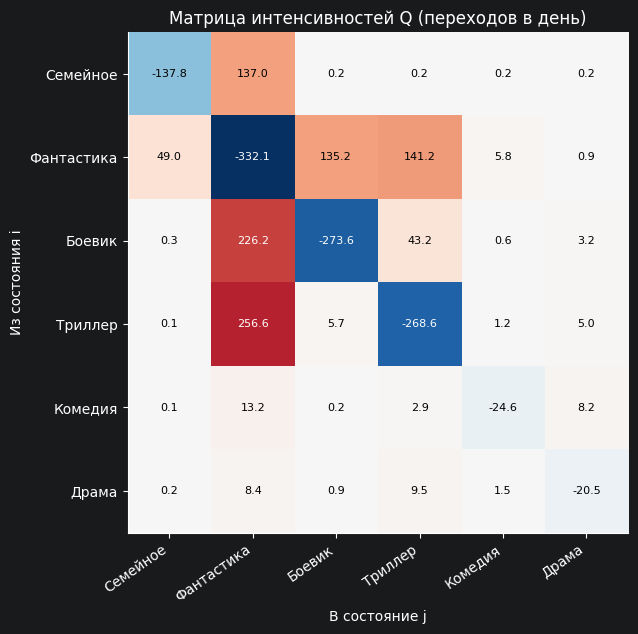

In [126]:
from scipy.optimize import minimize


def session_transitions(sessions):
    users = sessions["userId"].to_numpy()
    states = sessions["state"].to_numpy()
    starts = sessions["start"].to_numpy() / SECONDS_PER_DAY
    same = users[1:] == users[:-1]
    return states[:-1][same], states[1:][same], (starts[1:] - starts[:-1])[same]


def chain_rows(Q, start_dist, moments):
    # Распределение состояния start_dist @ exp(Q t) для каждой строки и каждого момента:
    # start_dist (n, S), moments (n, m) -> (n, m, S)
    lam, V = np.linalg.eig(Q)
    V_inv = np.linalg.inv(V)
    rows = np.einsum("nk,nmk,kj->nmj", start_dist @ V, np.exp(lam[None, None, :] * moments[:, :, None]), V_inv)
    return np.clip(rows.real, 1e-12, 1)


def fit_continuous_panel(prev, nxt, dt, Q_init):
    off_diagonal = ~np.eye(N_STATES, dtype=bool)

    def objective(log_rates):
        # P_ij(dt) = sum_k V_ik exp(lam_k dt) V^-1_kj - нужен только элемент (prev, next) каждого интервала
        lam, V = np.linalg.eig(rates_to_Q(np.exp(log_rates)))
        V_inv = np.linalg.inv(V)
        p = (V[prev] * np.exp(lam[None, :] * dt[:, None]) * V_inv[:, nxt].T).sum(axis=1).real
        return -np.log(np.clip(p, 1e-12, None)).mean()

    # EM-подобные задачи многоэкстремальны, поэтому оптимизация запускается из нескольких начальных точек:
    # из оценки способа 1 и из «быстро перемешивающихся» цепей со скоростью смены 1 и 0.1 раза в день
    shares = np.bincount(nxt, minlength=N_STATES) / len(nxt)
    starts = [Q_init] + [rate * (np.outer(np.ones(N_STATES), shares) - np.eye(N_STATES)) for rate in (1.0, 0.1)]
    best = None
    for Q_start in starts:
        x0 = np.log(np.clip(Q_start[off_diagonal], 1e-5, None))
        result = minimize(objective, x0, method="L-BFGS-B", bounds=[(-12, 6)] * len(x0))
        if best is None or result.fun < best.fun:
            best = result
    return rates_to_Q(np.exp(best.x)), best


prev_s, next_s, dt_s = session_transitions(sessions_full)
check_rows = chain_rows(Q_sojourn, np.eye(N_STATES)[prev_s[:200]], dt_s[:200, None])[:, 0]
exact_rows = np.array([expm(Q_sojourn * t)[i] for i, t in zip(prev_s[:200], dt_s[:200])])
print(f"Проверка спектрального расчёта exp(Qt) по scipy.linalg.expm: расхождение {np.abs(check_rows - exact_rows).max():.1e}")

start_time = time.time()
Q_panel, panel_result = fit_continuous_panel(prev_s, next_s, dt_s, Q_sojourn)
print(f"Оптимизация: {panel_result.nit} итераций, {time.time() - start_time:.1f} с, успех: {panel_result.success}")
print(f"Средний -log P на интервал между сессиями: {panel_result.fun:.4f}")

Q = Q_panel
fig, ax = plt.subplots(figsize=(8.5, 6.5))
limit = np.abs(Q).max()
show_matrix(ax, Q, STATES, STATES, "Матрица интенсивностей Q (переходов в день)", fmt="{:.1f}",
            cmap="RdBu_r", vmin=-limit, vmax=limit)
ax.set_xlabel("В состояние j")
ax.set_ylabel("Из состояния i")
plt.show()

На диагонали — отрицательные интенсивности ухода $-q_i$, вне диагонали — интенсивности переходов. Единица времени — день: интенсивность 24 означает в среднем одну смену группы в час.

Насколько модель согласуется с данными, видно по главному вопросу непрерывной цепи: **как вероятность остаться в той же группе зависит от паузы между сессиями**. Ниже — эмпирическая доля пар соседних сессий с одной и той же группой для разных интервалов и та же вероятность по модели.

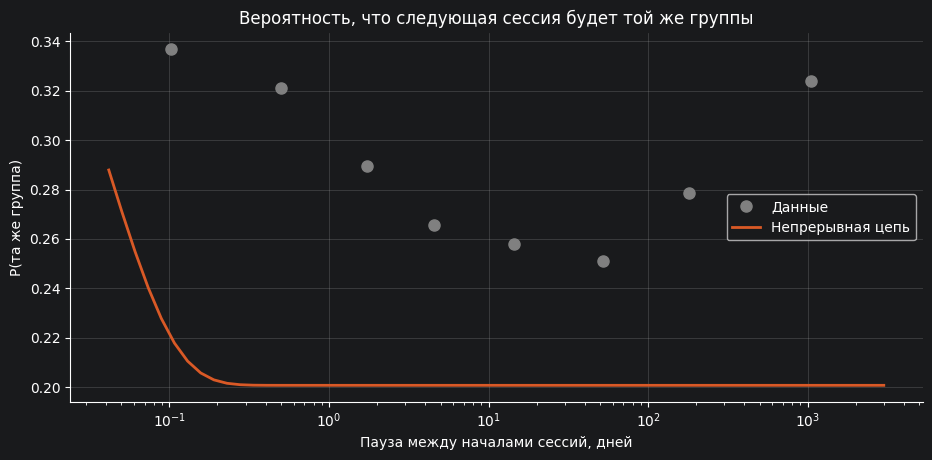

    mean  size    center
0  0.337  1452     0.102
1  0.321  1962     0.500
2  0.289  2706     1.732
3  0.265  2682     4.583
4  0.258  4077    14.491
5  0.251  1606    51.962
6  0.279   865   181.246
7  0.324   145  1046.422


In [127]:
dt_edges = np.array([1 / 24, 0.25, 1, 3, 7, 30, 90, 365, 3000])
dt_centers = np.sqrt(dt_edges[:-1] * dt_edges[1:])
bin_index = np.digitize(dt_s, dt_edges) - 1
valid_bins = (bin_index >= 0) & (bin_index < len(dt_centers))
same_group = (prev_s == next_s).astype(float)
empirical = pd.Series(same_group[valid_bins]).groupby(bin_index[valid_bins]).agg(["mean", "size"])

# Модельная вероятность остаться: усредняем p_ii(t) по фактическим состояниям внутри каждого интервала
t_line = np.logspace(np.log10(dt_edges[0]), np.log10(dt_edges[-1]), 60)
start_shares = np.bincount(prev_s, minlength=N_STATES) / len(prev_s)


def stay_probability(Q):
    rows = chain_rows(Q, np.eye(N_STATES), np.tile(t_line, (N_STATES, 1)))   # (S, моменты, S)
    return (start_shares[:, None] * rows[np.arange(N_STATES), :, np.arange(N_STATES)]).sum(axis=0)


plt.figure(figsize=(11, 4.8))
plt.plot(dt_centers[empirical.index], empirical["mean"], "o", color="gray", markersize=8, label="Данные")
plt.plot(t_line, stay_probability(Q), color=PALETTE[1], label="Непрерывная цепь")
plt.xscale("log")
plt.xlabel("Пауза между началами сессий, дней")
plt.ylabel("P(та же группа)")
plt.title("Вероятность, что следующая сессия будет той же группы")
plt.legend()
plt.show()
print(empirical.assign(center=dt_centers[empirical.index]).round(3).to_string())

Модель воспроизводит повышенную вероятность остаться в той же группе только в первые часы после сессии, а дальше её прогноз выходит на стационарный уровень. В данных же доля сессий той же группы остаётся выше этого уровня при любой паузе — даже через год. Причина в том, что у каждого зрителя есть **устойчивый личный вкус**: он чаще возвращается к «своей» группе независимо от того, сколько прошло времени. Общая для всех зрителей цепь этого учесть не может — её стационарное распределение одно на всех. Поэтому максимум правдоподобия достигается при быстром перемешивании: так одна общая цепь лучше всего описывает слабую зависимость группы от паузы.

## Свойства непрерывной цепи

In [128]:
pi_continuous = stationary_distribution(np.eye(N_STATES) + Q / np.abs(np.diag(Q)).max())   # pi Q = 0
jump_chain = Q / -np.diag(Q)[:, None]
np.fill_diagonal(jump_chain, 0)

continuous_table = pd.DataFrame({
    "Интенсивность ухода q_i, 1/день": -np.diag(Q),
    "Среднее пребывание, дней": 1 / -np.diag(Q),
    "Среднее пребывание, минут": 24 * 60 / -np.diag(Q),
    "pi стационарное": pi_continuous,
    "Доля сессий в данных": np.bincount(sessions_full["state"], minlength=N_STATES) / len(sessions_full),
}, index=STATES)
print(continuous_table.round(4).to_string())
print(f"\nПроверка pi Q = 0: max|pi Q| = {np.abs(pi_continuous @ Q).max():.1e}")

            Интенсивность ухода q_i, 1/день  Среднее пребывание, дней  Среднее пребывание, минут  pi стационарное  Доля сессий в данных
Семейное                           137.7841                    0.0073                    10.4511           0.1118                0.1063
Фантастика                         332.1414                    0.0030                     4.3355           0.3122                0.3517
Боевик                             273.5721                    0.0037                     5.2637           0.1590                0.1480
Триллер                            268.5814                    0.0037                     5.3615           0.1953                0.1866
Комедия                             24.6230                    0.0406                    58.4820           0.0962                0.0894
Драма                               20.4870                    0.0488                    70.2885           0.1255                0.1180

Проверка pi Q = 0: max|pi Q| = 1.1e-13


Стационарное распределение непрерывной цепи — доля **времени**, которую зритель в долгосрочной перспективе проводит в каждом состоянии. Оно близко к доле сессий каждой группы в данных.

(Для расчёта $\pi Q = 0$ используется та же функция, что для дискретной цепи: матрица $I + Q/\max_i q_i$ — стохастическая, и её стационарное распределение совпадает с решением $\pi Q = 0$.)

## Состояние системы в момент времени $t$

Матрица $P(t) = e^{Qt}$ для нескольких интервалов после начала сессии: 10 минут, 1 час, 6 часов, сутки.

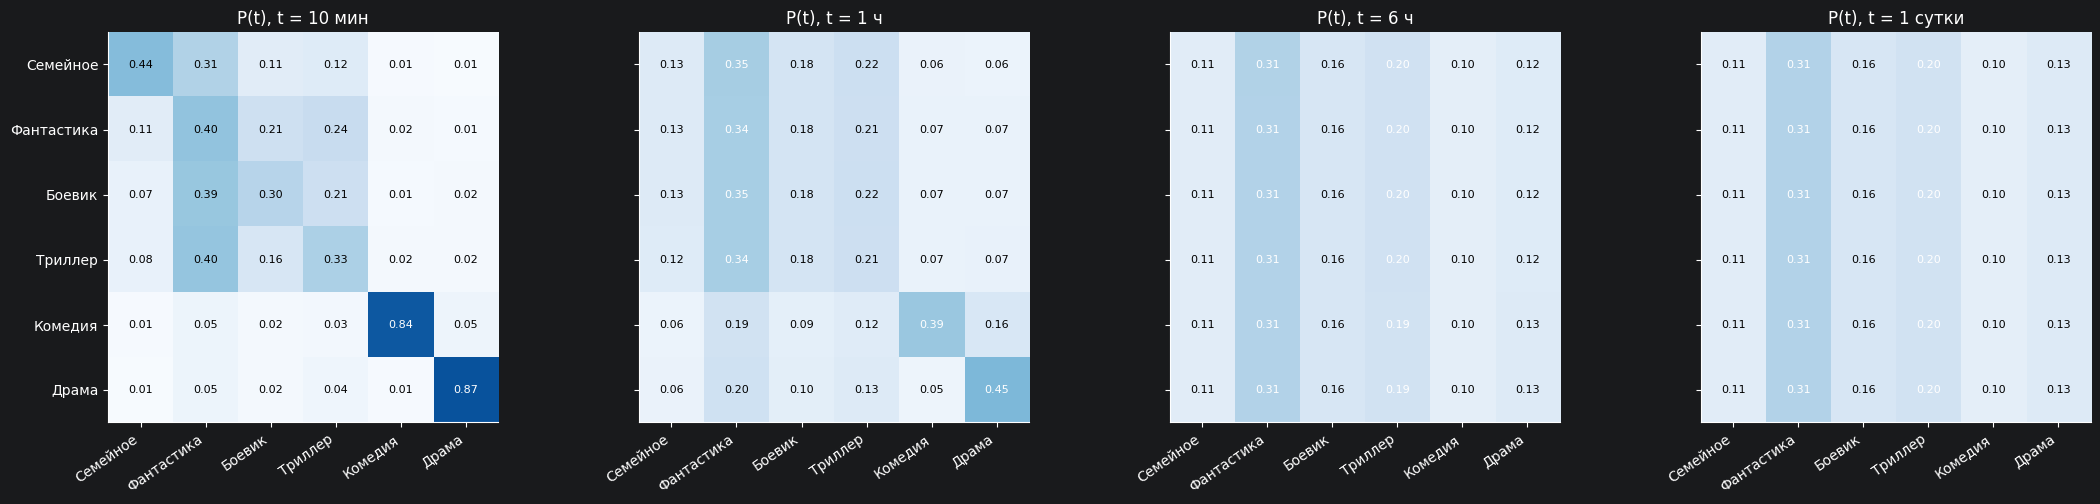

Проверка P'(t) = P(t) Q при t = 1 ч: относительное расхождение 1.1e-09


In [129]:
T_POINTS = [10 / 1440, 1 / 24, 6 / 24, 1]
T_LABELS = ["10 мин", "1 ч", "6 ч", "1 сутки"]
fig, axes = plt.subplots(1, len(T_POINTS), figsize=(22, 5))
for ax, t, label in zip(axes, T_POINTS, T_LABELS):
    show_matrix(ax, expm(Q * t), STATES, STATES, f"P(t), t = {label}", vmin=0, vmax=1)
    if ax is not axes[0]:
        ax.set_yticklabels([])
plt.tight_layout()
plt.show()

# Проверка уравнения Колмогорова P'(t) = P(t) Q численной производной
t0 = 1 / 24                                  # через час
h = 1e-3 / np.abs(np.diag(Q)).max()          # шаг много меньше характерного времени цепи
derivative = (expm(Q * (t0 + h)) - expm(Q * (t0 - h))) / (2 * h)   # центральная разность
exact = expm(Q * t0) @ Q
print(f"Проверка P'(t) = P(t) Q при t = 1 ч: относительное расхождение "
      f"{np.abs(derivative - exact).max() / np.abs(exact).max():.1e}")

Траектории $\pi(t) = \pi(0)\,e^{Qt}$. Слева — старт в одном состоянии («Фантастика»), справа — вектор начальных состояний системы: распределение групп последних сессий всех зрителей в конце обучающего периода. Ось времени логарифмическая, пунктир — стационарное распределение.

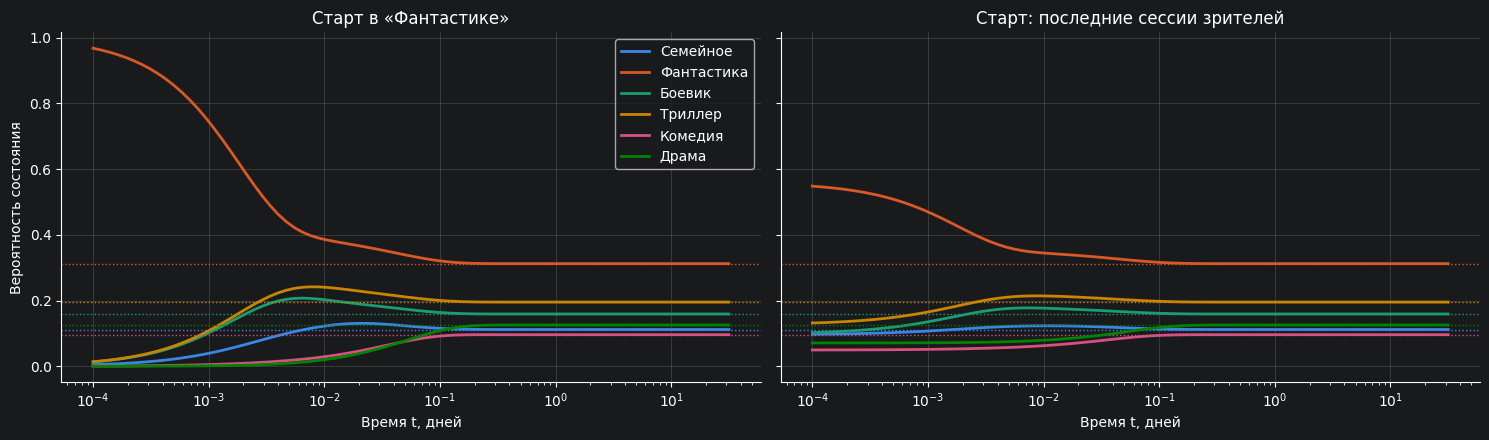

Состояние зрителя в момент t (старт в «Фантастике»):
         Семейное  Фантастика  Боевик  Триллер  Комедия  Драма
t                                                             
0           0.000       1.000   0.000    0.000    0.000  0.000
10 мин      0.113       0.403   0.207    0.241    0.022  0.013
1 ч         0.125       0.345   0.177    0.215    0.070  0.069
6 ч         0.112       0.312   0.159    0.195    0.096  0.125
1 сутки     0.112       0.312   0.159    0.195    0.096  0.126
7 суток     0.112       0.312   0.159    0.195    0.096  0.126

Время релаксации 1/|lambda_2| = 58 минут: за это время отклонение от стационарного распределения уменьшается в e раз


In [130]:
t_grid = np.logspace(-4, 1.5, 80)
last_session_state = sessions_full.groupby("userId")["state"].last()
pi0_continuous = np.bincount(last_session_state, minlength=N_STATES) / len(last_session_state)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, (title, start) in zip(axes, [("Старт в «Фантастике»", np.eye(N_STATES)[1]),
                                     ("Старт: последние сессии зрителей", pi0_continuous)]):
    trajectory = np.array([start @ expm(Q * t) for t in t_grid])
    for j, name in enumerate(STATES):
        ax.plot(t_grid, trajectory[:, j], color=PALETTE[j], label=name)
        ax.axhline(pi_continuous[j], color=PALETTE[j], linestyle=":", linewidth=1)
    ax.set_xscale("log")
    ax.set_xlabel("Время t, дней")
    ax.set_title(title)
axes[0].set_ylabel("Вероятность состояния")
axes[0].legend(loc="upper right")
plt.tight_layout()
plt.show()

moments_print = [0] + T_POINTS + [7]
state_by_time = pd.DataFrame([np.eye(N_STATES)[1] @ expm(Q * t) for t in moments_print],
                             index=pd.Index(["0"] + T_LABELS + ["7 суток"], name="t"), columns=STATES)
print("Состояние зрителя в момент t (старт в «Фантастике»):")
print(state_by_time.round(3).to_string())

second = np.sort(np.abs(np.linalg.eigvals(Q).real))[1]   # наименьшая по модулю ненулевая скорость
print(f"\nВремя релаксации 1/|lambda_2| = {24 * 60 / second:.0f} минут: за это время отклонение от стационарного "
      f"распределения уменьшается в e раз")

Цепь скачков (куда зритель переходит при смене группы) — вероятности $q_{ij}/q_i$:

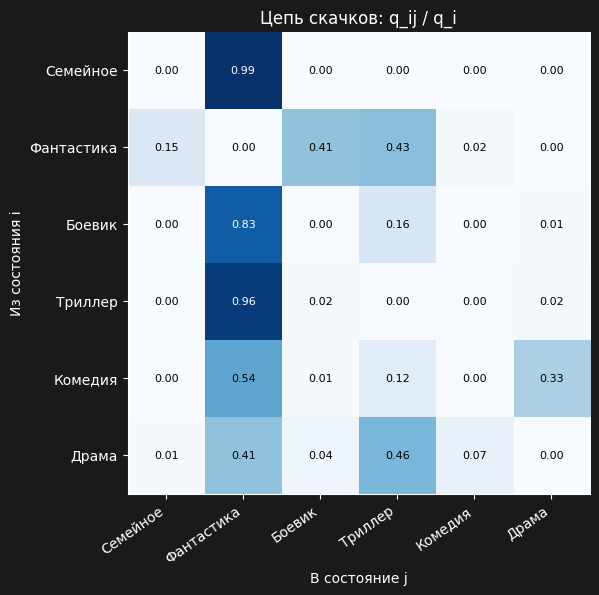

In [131]:
fig, ax = plt.subplots(figsize=(8, 6))
show_matrix(ax, jump_chain, STATES, STATES, "Цепь скачков: q_ij / q_i", vmin=0, vmax=1)
ax.set_xlabel("В состояние j")
ax.set_ylabel("Из состояния i")
plt.show()

# Применение цепей в рекомендательной системе

Теперь применим модели к конкретным зрителям и проверим их на тестовой выборке, которую модели не видели:
1. **Прогноз группы следующего фильма** — персональная дискретная цепь.
2. **Прогноз группы следующей сессии с учётом времени** — непрерывная цепь.
3. **Топ-N рекомендации фильмов** — дискретная цепь, состояниями которой являются отдельные фильмы.

Для каждой задачи приводится простой ориентир (модель без учёта последовательности), чтобы было видно, что даёт цепь.

Подготовка: индексы зрителей и фильмов, личные счётчики переходов и данные о фильмах.

In [132]:
user_ids = np.sort(pd.concat([train_full["userId"], test["userId"]]).unique())
movie_ids = np.sort(movies["movieId"].unique())
user_index = pd.Index(user_ids)
movie_index = pd.Index(movie_ids)
n_users, n_movies = len(user_ids), len(movie_ids)
TOP_N = 10

u_all = user_index.get_indexer(seq_full["userId"])
s_all = seq_full["state"].to_numpy()
same_user = u_all[1:] == u_all[:-1]
C_ratings = np.zeros((n_users, N_STATES, N_STATES))          # личные счётчики переходов
np.add.at(C_ratings, (u_all[1:][same_user], s_all[:-1][same_user], s_all[1:][same_user]), 1)

last_sessions = sessions_full.groupby("userId").tail(1).set_index("userId").reindex(user_ids)
M_train = np.zeros((n_users, n_movies), dtype=bool)          # что зритель уже оценил
M_train[u_all, movie_index.get_indexer(seq_full["movieId"])] = True
liked = seq_full[seq_full["rating"] >= mc.RELEVANCE_THRESHOLD]
popularity = liked["movieId"].value_counts().reindex(movie_ids, fill_value=0).to_numpy() + 0.1

full = {
    "seq": seq_full, "P_r": P_ratings, "Q": Q, "C_r": C_ratings,
    "freq": state_freq,
    "session_freq": np.bincount(sessions_full["state"], minlength=N_STATES) / len(sessions_full),
    "last_state": seq_full.groupby("userId")["state"].last().reindex(user_ids).to_numpy(),
    "last_session_state": last_sessions["state"].to_numpy().astype(int),
    "last_session_start": last_sessions["start"].to_numpy() / SECONDS_PER_DAY,
    "last_session_shares": session_shares_full.loc[list(zip(last_sessions.index, last_sessions["session"]))].to_numpy(),
    "M": M_train, "popularity": popularity,
}
print(f"Зрителей: {n_users:,}, фильмов: {n_movies:,}")

Зрителей: 1,988, фильмов: 2,191


## Прогноз группы следующего фильма: персональная цепь

Общая матрица $P$ одинакова для всех зрителей, хотя у каждого свои привычки: один после фантастики почти всегда смотрит ещё фантастику, другой чередует жанры. **Персональная цепь** даёт каждому зрителю свою матрицу переходов, «стянутую» к общей:
$$p^{(u)}_{ij} = \frac{n^{(u)}_{ij} + \beta\, p_{ij}}{n^{(u)}_i + \beta}.$$
При малом числе личных переходов из состояния $i$ прогноз близок к общей матрице, при большом — к личной статистике. Это байесовская оценка с априорным распределением Дирихле: $\beta$ — «вес» общей матрицы в штуках переходов; выбрано $\beta = 30$.

Для каждой оценки из тестовой выборки модель по предыдущей оценке зрителя выдаёт распределение вероятностей группы, и оно сравнивается с фактической группой. Метрики:
- **log-loss** — средний $-\ln p(\text{фактическая группа})$; чем меньше, тем лучше. Главная метрика: она оценивает всё распределение, а не только самую вероятную группу;
- **перплексия** $= e^{\text{log-loss}}$ — «из скольких равновероятных вариантов в среднем выбирает модель»; при угадывании наугад из 6 групп она равна 6;
- **точность** — доля случаев, когда самая вероятная группа совпала с фактической.

Ориентир — **доли групп**: всегда одно и то же распределение, без учёта предыстории.

In [133]:
BETA = 30


def eval_ratings(train_part, eval_part):
    # Позиции оценок из eval_part и предыдущая оценка того же зрителя
    both = pd.concat([train_part.assign(is_eval=False), eval_part.assign(is_eval=True)], ignore_index=True)
    seq = add_states(both)
    idx = np.flatnonzero(seq["is_eval"].to_numpy())
    states = seq["state"].to_numpy()
    return {"user": user_index.get_indexer(seq["userId"].to_numpy()[idx]),
            "prev": states[idx - 1], "actual": states[idx]}


def shrink(counts, prior, beta):
    # Байесовское сглаживание личных счётчиков к общему распределению
    return (counts + beta * prior) / (counts.sum(axis=-1, keepdims=True) + beta)


def next_state_metrics(probs, actual):
    p = np.clip(probs[np.arange(len(actual)), actual], 1e-12, None)
    log_loss = float(-np.mean(np.log(p)))
    return {"Log-loss": log_loss, "Перплексия": float(np.exp(log_loss)),
            "Точность": float(np.mean(probs.argmax(axis=1) == actual))}


ev_test = eval_ratings(train_full, test)
personal_probs = shrink(full["C_r"][ev_test["user"], ev_test["prev"]], full["P_r"][ev_test["prev"]], BETA)

next_results = [
    {"Модель": "Доли групп (ориентир)",
     **next_state_metrics(np.tile(full["freq"], (len(ev_test["actual"]), 1)), ev_test["actual"])},
    {"Модель": "Персональная цепь", **next_state_metrics(personal_probs, ev_test["actual"])},
]
print(f"Прогнозируемых оценок: {len(ev_test['actual']):,}")
print(pd.DataFrame(next_results).set_index("Модель").round(4).to_string())

Прогнозируемых оценок: 35,018
                       Log-loss  Перплексия  Точность
Модель                                               
Доли групп (ориентир)    1.7408      5.7018    0.2855
Персональная цепь        1.6643      5.2822    0.3132


## Прогноз группы следующей сессии: непрерывная цепь

Для каждой сессии, начавшейся в тестовой части, по группе предыдущей сессии зрителя $i$ и интервалу $\Delta t$ между их началами непрерывная цепь даёт распределение группы новой сессии — строку $i$ матрицы $P(\Delta t) = e^{Q\Delta t}$. Ориентир — **доли сессий** каждой группы, без учёта предыстории.

Сессии строятся по всей последовательности зрителя (обучающая и тестовая части вместе), чтобы сессия, которую разрезала граница частей, осталась одной сессией — иначе появились бы искусственные «сессии» с интервалом в минуты.

In [134]:
def eval_sessions(train_part, eval_part):
    # Сессии строятся по объединённой последовательности, чтобы сессия, разрезанная границей
    # обучающей и оценочной частей, не распалась на две искусственные. Прогнозируются сессии,
    # которые начались в оценочной части; предыдущая сессия - та, что была перед ними.
    seq = add_states(pd.concat([train_part, eval_part], ignore_index=True))
    sessions, _ = session_table(seq)
    eval_start = eval_part.groupby("userId")["timestamp"].min()
    is_eval = sessions["start"].to_numpy() >= sessions["userId"].map(eval_start).to_numpy()
    users = sessions["userId"].to_numpy()
    states = sessions["state"].to_numpy()
    starts = sessions["start"].to_numpy() / SECONDS_PER_DAY
    idx = np.flatnonzero(is_eval)
    idx = idx[(idx > 0) & (users[np.maximum(idx - 1, 0)] == users[idx])]
    return {"user": user_index.get_indexer(users[idx]), "prev": states[idx - 1],
            "actual": states[idx], "dt": starts[idx] - starts[idx - 1]}


evs_test = eval_sessions(train_full, test)
continuous_probs = chain_rows(Q, np.eye(N_STATES)[evs_test["prev"]], evs_test["dt"][:, None])[:, 0]

session_results = [
    {"Модель": "Доли сессий (ориентир)",
     **next_state_metrics(np.tile(full["session_freq"], (len(evs_test["actual"]), 1)), evs_test["actual"])},
    {"Модель": "Непрерывная цепь", **next_state_metrics(continuous_probs, evs_test["actual"])},
]
print(f"Прогнозируемых сессий: {len(evs_test['actual']):,}, "
      f"медианный интервал до них: {np.median(evs_test['dt']):.1f} дн.")
print(pd.DataFrame(session_results).set_index("Модель").round(4).to_string())

Прогнозируемых сессий: 7,864, медианный интервал до них: 7.0 дн.
                        Log-loss  Перплексия  Точность
Модель                                                
Доли сессий (ориентир)    1.7429      5.7137    0.2752
Непрерывная цепь          1.7308      5.6453    0.2762


## Топ-N рекомендации фильмов: цепь на уровне фильмов

Цепь с 6 жанровыми группами хорошо подходит для описания поведения зрителей, но для рекомендаций она слишком груба: она прогнозирует только **группу**, а внутри группы фильмы пришлось бы упорядочивать по популярности одинаково для всех зрителей. На этапе исследования сравнивались цепи с разной детализацией состояний — жанровые группы, автоматические кластеры фильмов по жанрам и по аудитории — и лучшее качество на валидации дала цепь, в которой **каждый фильм является отдельным состоянием**.

**Матрица переходов «фильм → фильм».** Состояний столько же, сколько фильмов (около 2.2 тыс.), то есть клеток почти 5 млн при 140 тыс. оценок. Чтобы оценки были устойчивыми, сделано два шага:
- переход $j \to f$ засчитывается, если фильм $f$ оценён в пределах $W = 30$ следующих оценок после $j$ (а не только сразу следующим) — это уплотняет статистику, учитывая, что оценки ставятся пачками и порядок внутри пачки случаен;
- строки сглаживаются к популярности фильмов:
$$p_{jf} = \frac{n_{jf} + \alpha\, \text{pop}_f / \sum \text{pop}}{n_j + \alpha}, \qquad \alpha = 5.$$

**Вектор начальных состояний** зрителя распределён поровну по его последним $L = 20$ фильмам. Вероятность того, что следующим будет фильм $f$, — $\pi^{(0)}_u P$; рекомендуются 10 фильмов с наибольшей вероятностью среди ещё не оценённых.

Ориентир — **популярное**: 10 самых популярных фильмов, как в работе №1. Метрики — те же, что в работе №1: Precision@10, Recall@10, NDCG@10 и покрытие каталога.

In [135]:
ITEM_WINDOW = 30
ITEM_RECENT = 20
ITEM_ALPHA = 5


def item_transition_matrix(train_part, window=ITEM_WINDOW, alpha=ITEM_ALPHA):
    seq = train_part.sort_values(["userId", "timestamp", "movieId"])
    u = user_index.get_indexer(seq["userId"])
    m = movie_index.get_indexer(seq["movieId"])
    N = np.zeros((n_movies, n_movies), dtype=np.float32)
    for d in range(1, window + 1):
        same = u[d:] == u[:-d]
        np.add.at(N, (m[:-d][same], m[d:][same]), 1)
    pop = (popularity / popularity.sum()).astype(np.float32)
    return (N + alpha * pop[None, :]) / (N.sum(axis=1, keepdims=True) + alpha)


def recent_start_vectors(train_part, recent=ITEM_RECENT):
    # Вектор начальных состояний: равные доли последних recent фильмов зрителя
    tail = train_part.sort_values(["userId", "timestamp", "movieId"]).groupby("userId").tail(recent)
    start = np.zeros((n_users, n_movies), dtype=np.float32)
    np.add.at(start, (user_index.get_indexer(tail["userId"]), movie_index.get_indexer(tail["movieId"])), 1)
    return start / start.sum(axis=1, keepdims=True)


def recommend(scores, n=TOP_N):
    scores = np.where(full["M"], -np.inf, scores + 1e-9 * popularity / popularity.max())
    top = np.argpartition(-scores, n, axis=1)[:, :n]
    order = np.argsort(-np.take_along_axis(scores, top, axis=1), axis=1)
    top = np.take_along_axis(top, order, axis=1)
    return {user_ids[u]: movie_ids[top[u]].tolist() for u in range(n_users)}


def evaluate_topn(recs, eval_df, n=TOP_N):
    metrics = mc.ranking_metrics(recs, eval_df, k=n)
    metrics.pop("users")
    recommended = set()
    for user in eval_df["userId"].unique():
        recommended.update(recs[user][:n])
    metrics["Покрытие каталога"] = len(recommended) / n_movies
    return metrics


@measure_resources
def build_item_chain():
    P_items = item_transition_matrix(train_full)
    start = recent_start_vectors(train_full)
    return P_items, start @ P_items


P_items, item_scores = build_item_chain()
print(f"Матрица переходов: {P_items.shape[0]} x {P_items.shape[1]} состояний")

test_recs = {
    "Популярное (ориентир)": recommend(np.tile(popularity, (n_users, 1))),
    "Цепь на уровне фильмов": recommend(item_scores),
}
topn_results = [{"Метод": name, **evaluate_topn(recs, test)} for name, recs in test_recs.items()]


def topn_table():
    return pd.DataFrame(topn_results).set_index("Метод")


print(topn_table().round(4).to_string())

Время: 1.67с
Память: +36.2 MB (макс: 462.9 MB)
Матрица переходов: 2191 x 2191 состояний
                        Precision@10  Recall@10  NDCG@10  Покрытие каталога
Метод                                                                      
Популярное (ориентир)         0.0647     0.0886   0.0937             0.0447
Цепь на уровне фильмов        0.0727     0.0995   0.1037             0.1465


Сравнение с анамнестическими методами из работы №1 (если рядом лежит файл `work1_results.csv`):

In [136]:
work1_path = Path("work1_results.csv")
if work1_path.exists():
    work1 = pd.read_csv(work1_path, index_col=0)
    work1_rows = work1.loc[work1["NDCG@10"].notna(), ["Precision@10", "Recall@10", "NDCG@10", "Покрытие каталога"]]
    work1_best = work1_rows.sort_values("NDCG@10", ascending=False).head(3)
    comparison = pd.concat([topn_table()[["Precision@10", "Recall@10", "NDCG@10", "Покрытие каталога"]],
                            work1_best.rename(index=lambda name: f"Работа 1: {name}")])
    print(comparison.sort_values("NDCG@10", ascending=False).round(4).to_string())
else:
    print("Файл work1_results.csv не найден - сравнение пропущено")

                                         Precision@10  Recall@10  NDCG@10  Покрытие каталога
Метод                                                                                       
Работа 1: user-based: Косинус                  0.0823     0.1206   0.1210             0.1109
Работа 1: Своё: выбор метода по отзывам        0.0833     0.1195   0.1209             0.2049
Работа 1: Гибрид: RRF                          0.0844     0.1204   0.1206             0.1538
Цепь на уровне фильмов                         0.0727     0.0995   0.1037             0.1465
Популярное (ориентир)                          0.0647     0.0886   0.0937             0.0447


# Дополнительно: скрытая Марковская модель

## Модель

В обычной цепи состояние наблюдаемо: мы видим группу фильма. Но выбор зрителя определяется тем, чего мы не видим, — его **настроением** или «режимом просмотра»: вечер лёгкого кино с семьёй, полоса серьёзных фильмов, марафон блокбастеров. Такой режим может длиться несколько фильмов подряд и в каждом режиме выбираются разные группы, но с разными вероятностями.

**Скрытая Марковская модель (СММ)** $\lambda = (A, B, \pi)$:
- $K$ скрытых состояний (режимов), между ними — Марковская цепь с матрицей переходов $A = (a_{kl})$ и начальным распределением $\pi$;
- в каждом скрытом состоянии $k$ наблюдается символ (группа фильма) с вероятностями $B = (b_k(o))$ — **матрица эмиссий**;
- наблюдаемая последовательность групп $O = o_1, o_2, \dots, o_T$ — результат: режим меняется по цепи $A$, на каждом шаге режим «испускает» группу по $B$.

Три классические задачи СММ (Примечание 2 методички):
1. **Оценка модели** — вероятность последовательности наблюдений $P(O \mid \lambda)$. Решается **прямым-обратным алгоритмом** (forward–backward). Прямые переменные $\alpha_t(k) = P(o_1, \dots, o_t, q_t = k)$ считаются рекуррентно:
$$\alpha_1(k) = \pi_k b_k(o_1), \qquad \alpha_{t+1}(l) = \Big[\sum_k \alpha_t(k)\, a_{kl}\Big] b_l(o_{t+1}), \qquad P(O \mid \lambda) = \sum_k \alpha_T(k).$$
Обратные переменные $\beta_t(k) = P(o_{t+1}, \dots, o_T \mid q_t = k)$ считаются от конца к началу.
2. **Оценка состояния** — наиболее вероятная последовательность скрытых состояний $\arg\max_Q P(Q \mid O, \lambda)$. Решается **алгоритмом Витерби**: та же рекурсия, что для $\alpha$, но сумма заменена на максимум, а лучший предшественник запоминается для обратного прохода.
3. **Обучение** — параметры $\lambda$, максимизирующие $P(O \mid \lambda)$. Решается **алгоритмом Баума — Велша** (частный случай EM-алгоритма): по $\alpha$ и $\beta$ вычисляются ожидаемые числа пребываний в состояниях и переходов между ними, и по ним пересчитываются $A$, $B$, $\pi$. Каждая итерация не уменьшает правдоподобие.

На длинных последовательностях $\alpha_t$ становятся меньше машинной точности, поэтому используется **нормировка**: на каждом шаге $\alpha_t$ делится на $c_t = \sum_k \alpha_t(k)$, и $\log P(O \mid \lambda) = \sum_t \log c_t$. Множитель $c_t$ имеет смысл: это $P(o_t \mid o_1, \dots, o_{t-1})$ — вероятность очередного наблюдения при известной предыстории, то есть именно прогноз следующей группы.

Все алгоритмы реализованы вручную на numpy и обрабатывают последовательности всех зрителей одновременно: последовательности записываются в матрицу «зритель × шаг», упорядоченную по убыванию длины. Тогда на шаге $t$ ещё не закончились последовательности первых $n_t$ строк, и вычисления идут только по ним — без лишней работы над пропусками.

In [137]:
def pad_sequences(seq_list):
    # Матрица «последовательность × шаг», строки упорядочены по убыванию длины.
    # order[i] - номер исходной последовательности в строке i
    lengths = np.array([len(s) for s in seq_list])
    order = np.argsort(-lengths, kind="stable")
    O = np.zeros((len(seq_list), lengths.max()), dtype=int)
    mask = np.zeros(O.shape, dtype=bool)
    for row, i in enumerate(order):
        O[row, :lengths[i]] = seq_list[i]
        mask[row, :lengths[i]] = True
    return O, mask, order


def hmm_forward(O, mask, pi, A, B):
    # Возвращает нормированные alpha (n, T, K) и множители c (n, T): c[:, t] = P(o_t | o_1..o_{t-1}).
    # На шаге t обрабатываются только первые active[t] строк - ещё не закончившиеся последовательности
    n, T = O.shape
    active = mask.sum(axis=0)
    alpha = np.zeros((n, T, len(pi)))
    c = np.ones((n, T))
    a = pi[None, :] * B[:, O[:, 0]].T
    c[:, 0] = a.sum(axis=1)
    alpha[:, 0] = a / c[:, 0, None]
    for t in range(1, T):
        m = active[t]
        a = (alpha[:m, t - 1] @ A) * B[:, O[:m, t]].T
        c[:m, t] = a.sum(axis=1)
        alpha[:m, t] = a / c[:m, t, None]
    return alpha, c


def hmm_backward(O, mask, A, B, c):
    n, T = O.shape
    active = mask.sum(axis=0)
    beta = np.ones((n, T, A.shape[0]))
    for t in range(T - 2, -1, -1):
        m = active[t + 1]
        beta[:m, t] = ((B[:, O[:m, t + 1]].T * beta[:m, t + 1]) @ A.T) / c[:m, t + 1, None]
    return beta


def hmm_loglik(O, mask, pi, A, B):
    _, c = hmm_forward(O, mask, pi, A, B)
    return np.log(c).sum(axis=1)


def viterbi(obs, pi, A, B):
    log_A, log_B = np.log(A + 1e-300), np.log(B + 1e-300)
    T, K = len(obs), len(pi)
    delta = np.log(pi + 1e-300) + log_B[:, obs[0]]
    psi = np.zeros((T, K), dtype=int)
    for t in range(1, T):
        candidates = delta[:, None] + log_A          # из состояния k в состояние l
        psi[t] = candidates.argmax(axis=0)
        delta = candidates.max(axis=0) + log_B[:, obs[t]]
    path = np.zeros(T, dtype=int)
    path[-1] = delta.argmax()
    for t in range(T - 1, 0, -1):
        path[t - 1] = psi[t, path[t]]
    return path, delta.max()

Проверка на игрушечном примере

Две скрытые «настроения» — «лёгкое» и «серьёзное» — и три наблюдаемые группы. Для короткой последовательности можно перебрать **все** $K^T$ последовательностей скрытых состояний: сумма их вероятностей должна совпасть с результатом прямого алгоритма, а самая вероятная — с результатом Витерби.

In [138]:
from itertools import product

toy_hidden = ["Лёгкое", "Серьёзное"]
toy_obs_names = ["Комедия", "Боевик", "Драма"]
toy_pi = np.array([0.6, 0.4])
toy_A = np.array([[0.8, 0.2],
                  [0.3, 0.7]])
toy_B = np.array([[0.6, 0.3, 0.1],     # в лёгком настроении - в основном комедии
                  [0.1, 0.3, 0.6]])    # в серьёзном - в основном драмы
toy_seq = np.array([0, 0, 1, 2, 2, 1])

# Полный перебор скрытых последовательностей
brute = {}
for path in product(range(2), repeat=len(toy_seq)):
    p = toy_pi[path[0]] * toy_B[path[0], toy_seq[0]]
    for t in range(1, len(toy_seq)):
        p *= toy_A[path[t - 1], path[t]] * toy_B[path[t], toy_seq[t]]
    brute[path] = p

forward_prob = np.exp(hmm_loglik(*pad_sequences([toy_seq])[:2], toy_pi, toy_A, toy_B))[0]
best_path, best_log = viterbi(toy_seq, toy_pi, toy_A, toy_B)
brute_best = max(brute, key=brute.get)

print("Наблюдения:", " → ".join(toy_obs_names[o] for o in toy_seq))
print(f"P(O) прямым алгоритмом:  {forward_prob:.8f}")
print(f"P(O) полным перебором:   {sum(brute.values()):.8f}  ({len(brute)} путей)")
print("Витерби:          ", " → ".join(toy_hidden[k] for k in best_path), f"(P = {np.exp(best_log):.6f})")
print("Перебор (лучший): ", " → ".join(toy_hidden[k] for k in brute_best), f"(P = {brute[brute_best]:.6f})")

Наблюдения: Комедия → Комедия → Боевик → Драма → Драма → Боевик
P(O) прямым алгоритмом:  0.00168075
P(O) полным перебором:   0.00168075  (64 путей)
Витерби:           Лёгкое → Лёгкое → Лёгкое → Серьёзное → Серьёзное → Серьёзное (P = 0.000439)
Перебор (лучший):  Лёгкое → Лёгкое → Лёгкое → Серьёзное → Серьёзное → Серьёзное (P = 0.000439)


## Обучение алгоритмом Баума — Велша

Формулы пересчёта параметров по всем последовательностям:
$$\gamma_t(k) = \alpha_t(k)\beta_t(k), \qquad \xi_t(k,l) = \frac{\alpha_t(k)\, a_{kl}\, b_l(o_{t+1})\, \beta_{t+1}(l)}{c_{t+1}},$$
$$\pi_k = \overline{\gamma_1(k)}, \qquad a_{kl} = \frac{\sum_t \xi_t(k,l)}{\sum_t \sum_{l'} \xi_t(k,l')}, \qquad b_k(o) = \frac{\sum_{t:\,o_t = o} \gamma_t(k)}{\sum_t \gamma_t(k)}.$$
$\gamma_t(k)$ — вероятность быть в скрытом состоянии $k$ на шаге $t$, $\xi_t(k,l)$ — вероятность перехода $k \to l$ между шагами $t$ и $t+1$ (с учётом всей последовательности).

EM-алгоритм находит локальный максимум, зависящий от начального приближения, поэтому обучение запускается из нескольких случайных начальных точек и выбирается лучшая.

Для обучения у каждого зрителя берутся последние `HMM_MAX_LEN` оценок: у самых активных зрителей тысячи оценок, и без ограничения матрица «зритель × шаг» состояла бы в основном из пропусков. Недавние оценки к тому же лучше отражают текущее поведение.

In [139]:
HMM_K = 6            # число скрытых состояний (выбрано по валидации на этапе исследования)
HMM_MAX_LEN = 500
HMM_RESTARTS = 2
HMM_MAX_ITER = 100
HMM_TOL = 1e-5


def user_sequences(seq, max_len=None):
    groups = seq.groupby("userId")["state"].apply(lambda s: s.to_numpy())
    groups = groups.reindex(user_ids)
    return [g[-max_len:] if max_len else g for g in groups]


def baum_welch(O, mask, K, rng):
    n_symbols = N_STATES
    pi = rng.dirichlet(np.ones(K))
    A = rng.dirichlet(np.ones(K), size=K) + np.eye(K)      # начальная «липкость» режимов
    A /= A.sum(axis=1, keepdims=True)
    B = rng.dirichlet(np.ones(n_symbols), size=K)
    n_obs = mask.sum()
    history = []
    for _ in range(HMM_MAX_ITER):
        alpha, c = hmm_forward(O, mask, pi, A, B)
        beta = hmm_backward(O, mask, A, B, c)
        history.append(np.log(c).sum() / n_obs)

        gamma = (alpha * beta)[mask]                     # (число наблюдений, K)
        active = mask.sum(axis=0)
        xi_sum = np.zeros((K, K))
        for t in range(O.shape[1] - 1):
            m = active[t + 1]
            w = B[:, O[:m, t + 1]].T * beta[:m, t + 1] / c[:m, t + 1, None]
            xi_sum += A * (alpha[:m, t].T @ w)

        pi = (alpha[:, 0] * beta[:, 0]).mean(axis=0)
        A = xi_sum / xi_sum.sum(axis=1, keepdims=True)
        observed = O[mask]
        B = np.stack([np.bincount(observed, weights=gamma[:, k], minlength=n_symbols) for k in range(K)])
        B = (B + 1e-6) / (B + 1e-6).sum(axis=1, keepdims=True)
        if len(history) > 1 and history[-1] - history[-2] < HMM_TOL:
            break
    return {"pi": pi, "A": A, "B": B, "history": history}


def train_hmm(seq_list, K, seed=42):
    O, mask, _ = pad_sequences(seq_list)
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(HMM_RESTARTS):
        model = baum_welch(O, mask, K, rng)
        if best is None or model["history"][-1] > best["history"][-1]:
            best = model
    return best

Обучение модели с $K = 6$ скрытыми состояниями на обучающей выборке и график сходимости алгоритма Баума — Велша: правдоподобие растёт на каждой итерации, как и должно быть у EM-алгоритма.

Обучение: 81 итераций, 30.7 с


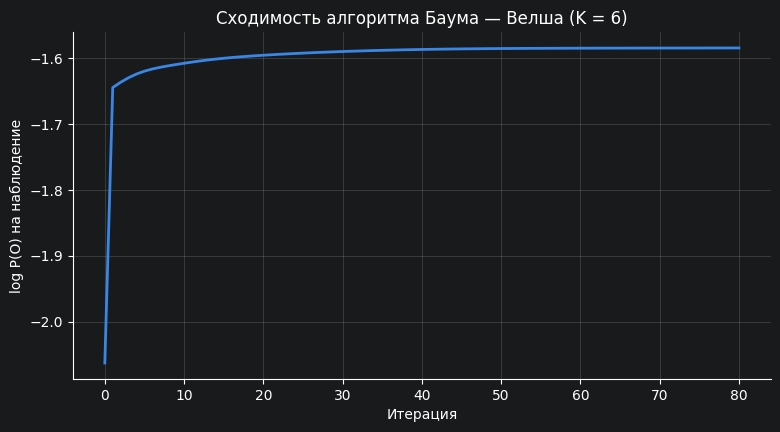

In [140]:
start_time = time.time()
hmm_full = train_hmm(user_sequences(full["seq"], HMM_MAX_LEN), HMM_K)
print(f"Обучение: {len(hmm_full['history'])} итераций, {time.time() - start_time:.1f} с")

plt.figure(figsize=(9, 4.5))
plt.plot(hmm_full["history"], color=MAIN_COLOR)
plt.xlabel("Итерация")
plt.ylabel("log P(O) на наблюдение")
plt.title(f"Сходимость алгоритма Баума — Велша (K = {HMM_K})")
plt.show()

Прогноз следующей группы скрытой моделью

СММ решает ту же задачу, что и персональная цепь, — прогноз группы следующего фильма. Прямой алгоритм прогоняется по последовательности «обучающая часть + тестовая часть», и для каждой тестовой позиции берётся $c_t = P(o_t \mid o_1, \dots, o_{t-1})$ — это ровно вероятность фактической группы. Прогнозное распределение целиком — $(\alpha_{t-1} A)\, B$.

In [141]:
def hmm_next_state_eval(model, train_seq, eval_part, train_part):
    both = add_states(pd.concat([train_part.assign(is_eval=False), eval_part.assign(is_eval=True)],
                                ignore_index=True))
    O_list, eval_flags = [], []
    train_lengths = train_seq["userId"].value_counts().reindex(user_ids).to_numpy()
    for i, (user, group) in enumerate(both.groupby("userId", sort=True)):
        states = group["state"].to_numpy()
        flags = group["is_eval"].to_numpy()
        start = max(0, train_lengths[i] - HMM_MAX_LEN)          # последние HMM_MAX_LEN обучающих оценок
        O_list.append(states[start:])
        eval_flags.append(flags[start:])
    O, mask, order = pad_sequences(O_list)
    flags = np.zeros(O.shape, dtype=bool)
    for row, i in enumerate(order):
        flags[row, :len(eval_flags[i])] = eval_flags[i]

    alpha, c = hmm_forward(O, mask, model["pi"], model["A"], model["B"])
    predictive = np.einsum("ntk,kl,ls->nts", alpha[:, :-1], model["A"], model["B"])   # прогноз для шага t+1
    positions = flags[:, 1:]
    probs = predictive[positions]
    actual = O[:, 1:][positions]
    return next_state_metrics(probs, actual)


next_results.append({"Модель": f"СММ (K = {HMM_K})",
                     **hmm_next_state_eval(hmm_full, full["seq"], test, train_full)})
next_table = pd.DataFrame(next_results).set_index("Модель")
print("Прогноз группы следующего фильма (test):")
print(next_table.round(4).to_string())

Прогноз группы следующего фильма (test):
                       Log-loss  Перплексия  Точность
Модель                                               
Доли групп (ориентир)    1.7408      5.7018    0.2855
Персональная цепь        1.6643      5.2822    0.3132
СММ (K = 6)              1.6434      5.1727    0.3259


## Интерпретация скрытых состояний

Матрица эмиссий $B$ показывает, какие группы выбирает зритель в каждом скрытом режиме, матрица $A$ — насколько режимы устойчивы. Каждому режиму дано название по группе с наибольшим **превышением** над общей долей (во сколько раз группа чаще, чем в среднем): так видно, чем режим отличается от остальных.

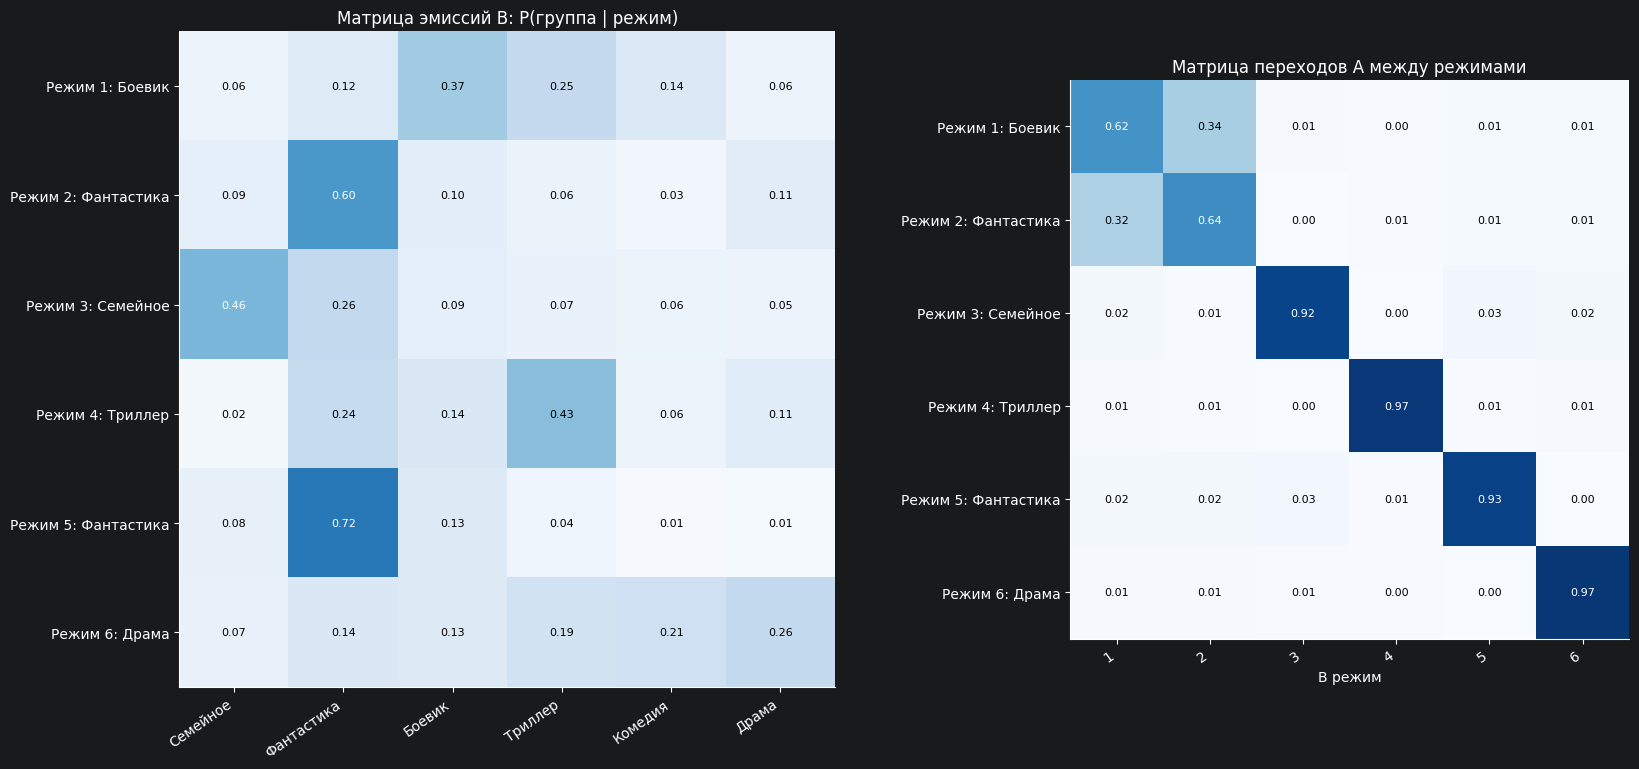

                     pi (начальное)  Устойчивость a_kk  Длительность режима, оценок  Стационарная доля
Режим 1: Боевик               0.111              0.619                        2.626              0.181
Режим 2: Фантастика           0.344              0.644                        2.810              0.191
Режим 3: Семейное             0.063              0.922                       12.740              0.101
Режим 4: Триллер              0.092              0.967                       30.116              0.127
Режим 5: Фантастика           0.223              0.932                       14.768              0.136
Режим 6: Драма                0.167              0.969                       32.776              0.265


In [142]:
hidden_lift = hmm_full["B"] / full["freq"][None, :]
best_K = HMM_K
hidden_names = [f"Режим {k + 1}: {STATES[hidden_lift[k].argmax()]}" for k in range(best_K)]

fig, axes = plt.subplots(1, 2, figsize=(17, 0.8 * best_K + 3), gridspec_kw={"width_ratios": [1.6, 1]})
show_matrix(axes[0], hmm_full["B"], hidden_names, STATES, "Матрица эмиссий B: P(группа | режим)", vmin=0, vmax=1)
show_matrix(axes[1], hmm_full["A"], hidden_names, [f"{k + 1}" for k in range(best_K)],
            "Матрица переходов A между режимами", vmin=0, vmax=1)
axes[1].set_xlabel("В режим")
plt.tight_layout()
plt.show()

hidden_table = pd.DataFrame({
    "pi (начальное)": hmm_full["pi"],
    "Устойчивость a_kk": np.diag(hmm_full["A"]),
    "Длительность режима, оценок": 1 / (1 - np.diag(hmm_full["A"])),
    "Стационарная доля": stationary_distribution(hmm_full["A"]),
}, index=hidden_names)
print(hidden_table.round(3).to_string())

## Оценка модели: вероятность последовательности наблюдений

Первая задача СММ — вычислить $P(O \mid \lambda)$. Сама по себе вероятность длинной последовательности ничтожно мала, поэтому сравнивается **средний логарифм вероятности на одно наблюдение**. Сравним реальные последовательности зрителей с теми же последовательностями, **перемешанными случайно**: состав групп у зрителя тот же, но порядок разрушен. Если модель уловила порядок просмотра, реальные последовательности должны быть для неё заметно вероятнее перемешанных. Для сравнения то же самое считается для цепи 1-го порядка и модели нулевого порядка (у последней разницы нет по определению).

In [143]:
def chain_loglik(seq_list, P, pi_start):
    total, count = 0.0, 0
    for s in seq_list:
        total += np.log(pi_start[s[0]]) + np.log(P[s[:-1], s[1:]]).sum()
        count += len(s)
    return total / count


rng = np.random.default_rng(0)
real_sequences = user_sequences(full["seq"], HMM_MAX_LEN)
shuffled_sequences = [rng.permutation(s) for s in real_sequences]
O_real, mask_real, _ = pad_sequences(real_sequences)
O_shuf, mask_shuf, _ = pad_sequences(shuffled_sequences)
n_obs = mask_real.sum()
freq_matrix = np.tile(full["freq"], (N_STATES, 1))

evaluation = pd.DataFrame({
    "Реальный порядок": [
        hmm_loglik(O_real, mask_real, hmm_full["pi"], hmm_full["A"], hmm_full["B"]).sum() / n_obs,
        chain_loglik(real_sequences, full["P_r"], full["freq"]),
        chain_loglik(real_sequences, freq_matrix, full["freq"])],
    "Перемешанный порядок": [
        hmm_loglik(O_shuf, mask_shuf, hmm_full["pi"], hmm_full["A"], hmm_full["B"]).sum() / n_obs,
        chain_loglik(shuffled_sequences, full["P_r"], full["freq"]),
        chain_loglik(shuffled_sequences, freq_matrix, full["freq"])],
}, index=[f"СММ (K = {best_K})", "Цепь 1-го порядка", "Доли групп"])
evaluation["Разница"] = evaluation["Реальный порядок"] - evaluation["Перемешанный порядок"]
evaluation["Во сколько раз вероятнее одно наблюдение"] = np.exp(evaluation["Разница"])
print("Средний log P на одно наблюдение (обучающие последовательности):")
print(evaluation.round(4).to_string())

Средний log P на одно наблюдение (обучающие последовательности):
                   Реальный порядок  Перемешанный порядок  Разница  Во сколько раз вероятнее одно наблюдение
СММ (K = 6)                 -1.5843               -1.6271   0.0428                                    1.0438
Цепь 1-го порядка           -1.6348               -1.6779   0.0431                                    1.0441
Доли групп                  -1.6783               -1.6783   0.0000                                    1.0000


## Оценка состояния: алгоритм Витерби

Вторая задача СММ — найти наиболее вероятную последовательность скрытых режимов для последовательности наблюдений. Для наглядности выбран зритель (среди тех, у кого не меньше 120 оценок), у которого режим меняется чаще всего. Ниже — его первые 120 оценок: сверху наблюдаемые группы фильмов, снизу — восстановленные алгоритмом Витерби режимы. Вертикальные линии — границы сессий.

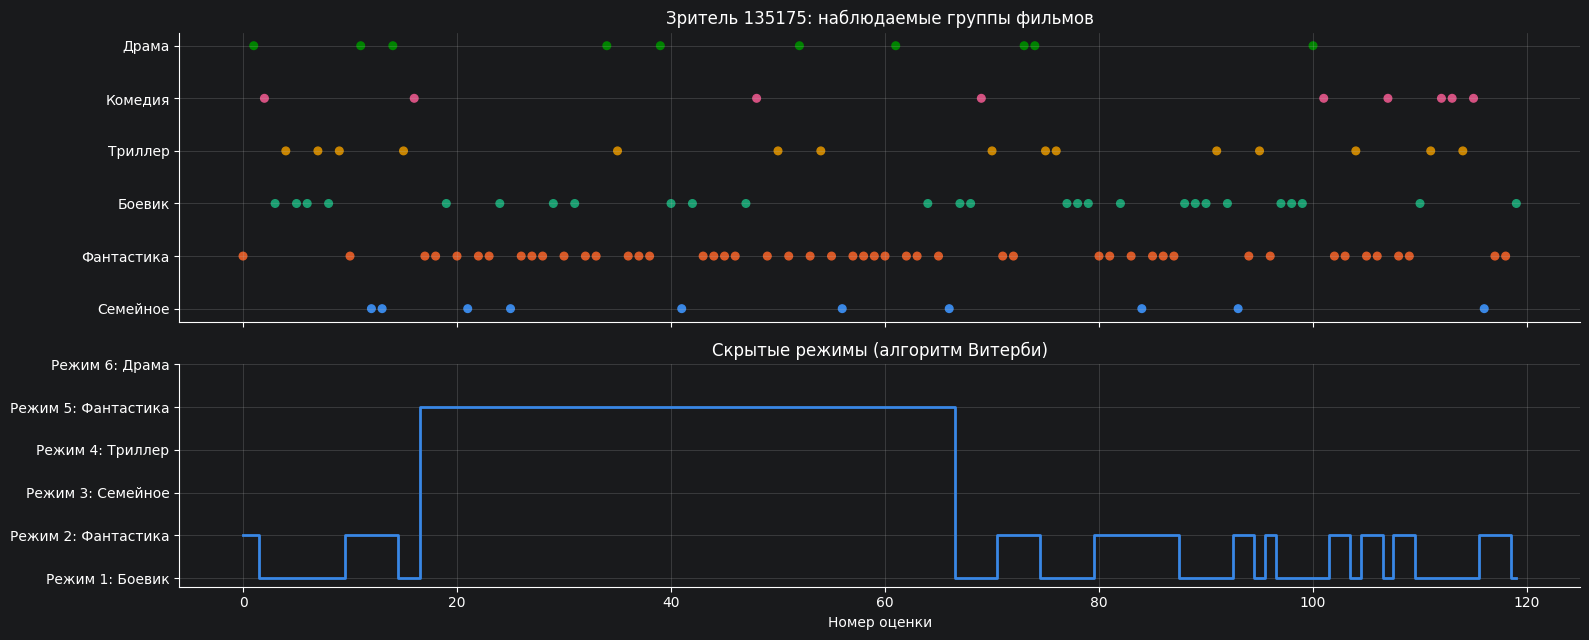

log P(O, Q*) лучшего пути: -215.0
log P(O) по всем путям:    -190.1
Смен режима: 21, смен группы фильма: 85


In [144]:
sequences_by_user = {user: group for user, group in full["seq"].groupby("userId") if len(group) >= 120}
switch_counts = {}
for user, group in sequences_by_user.items():
    path, _ = viterbi(group["state"].to_numpy()[:120], hmm_full["pi"], hmm_full["A"], hmm_full["B"])
    switch_counts[user] = (np.diff(path) != 0).sum()
viterbi_user = max(switch_counts, key=switch_counts.get)
user_seq = full["seq"][full["seq"]["userId"] == viterbi_user].head(120)
observed = user_seq["state"].to_numpy()
hidden_path, best_log_prob = viterbi(observed, hmm_full["pi"], hmm_full["A"], hmm_full["B"])
session_starts = np.flatnonzero(np.diff(user_seq["session"].to_numpy()) != 0) + 0.5

fig, axes = plt.subplots(2, 1, figsize=(16, 6.5), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
steps_axis = np.arange(len(observed))
axes[0].scatter(steps_axis, observed, c=[PALETTE[s] for s in observed], s=30)
axes[0].set_yticks(range(N_STATES))
axes[0].set_yticklabels(STATES)
axes[0].set_title(f"Зритель {viterbi_user}: наблюдаемые группы фильмов")
axes[1].step(steps_axis, hidden_path, where="mid", color=MAIN_COLOR)
axes[1].set_yticks(range(best_K))
axes[1].set_yticklabels(hidden_names)
axes[1].set_title("Скрытые режимы (алгоритм Витерби)")
axes[1].set_xlabel("Номер оценки")
for ax in axes:
    for boundary in session_starts:
        ax.axvline(boundary, color="gray", linewidth=0.6, alpha=0.5)
plt.tight_layout()
plt.show()

print(f"log P(O, Q*) лучшего пути: {best_log_prob:.1f}")
print(f"log P(O) по всем путям:    {hmm_loglik(*pad_sequences([observed])[:2], hmm_full['pi'], hmm_full['A'], hmm_full['B'])[0]:.1f}")
print(f"Смен режима: {(np.diff(hidden_path) != 0).sum()}, смен группы фильма: {(np.diff(observed) != 0).sum()}")

Скрытые режимы меняются реже, чем наблюдаемые группы: модель «сглаживает» случайные отклонения (одна комедия среди фантастики не меняет режим) и выделяет участки устойчивого поведения. Разница между $\log P(O, Q^*)$ и $\log P(O)$ показывает, какая доля вероятности приходится на один лучший путь: чем она меньше, тем увереннее восстановлены режимы.

# Пример для одного зрителя

Как модели видят одного и того же зрителя: его последние оценки, прогноз группы на несколько шагов вперёд персональной цепью, прогноз на момент возвращения непрерывной цепью и рекомендации цепи на уровне фильмов. Отмечены фильмы, которые зритель потом действительно оценил.

In [145]:
u = user_index.get_loc(example_user)
movie_info = movies.set_index("movieId")
history = full["seq"][full["seq"]["userId"] == example_user].tail(12)
print(f"Зритель {example_user}: последние оценки в обучающей выборке")
for _, row in history.iterrows():
    print(f"  сессия {row['session']:>3}  {row['rating']:.1f}  {STATES[row['state']]:<11} {movie_info.loc[row['movieId'], 'title']}")

P_user = shrink(full["C_r"][u], full["P_r"], BETA)
start = np.eye(N_STATES)[full["last_state"][u]]
steps_table = pd.DataFrame([start @ np.linalg.matrix_power(P_user, n) for n in [1, 2, 3, 5, 10]],
                           index=pd.Index([1, 2, 3, 5, 10], name="Шаг n"), columns=STATES)
print("\nПерсональная дискретная цепь: состояние на шаге n")
print(steps_table.round(3).to_string())

first_test = test.loc[test["userId"] == example_user, "timestamp"].min() / SECONDS_PER_DAY
gap = first_test - full["last_session_start"][u]
time_points = [gap, gap + 1 / 24, gap + 1]
time_table_user = pd.DataFrame([full["last_session_shares"][u] @ expm(Q * t) for t in time_points],
                               index=pd.Index([f"возвращение (+{gap:.1f} дн.)", "+1 час", "+1 сутки"], name="момент"),
                               columns=STATES)
print("\nНепрерывная цепь: распределение группы (старт - доли групп в последней сессии)")
print(time_table_user.round(3).to_string())

actual = test[test["userId"] == example_user].set_index("movieId")["rating"]
print("\nРекомендации — цепь на уровне фильмов:")
for movie_id in test_recs["Цепь на уровне фильмов"][example_user]:
    mark = f"  оценил потом на {actual[movie_id]:.1f}" if movie_id in actual.index else ""
    print(f"  {STATES[movie_info.loc[movie_id, 'state']]:<11} {movie_info.loc[movie_id, 'title']}{mark}")

Зритель 81271: последние оценки в обучающей выборке
  сессия 125  3.0  Триллер     Pig (2021)
  сессия 126  3.5  Фантастика  Free Guy (2020)
  сессия 127  3.5  Боевик      Old Henry (2021)
  сессия 128  4.0  Фантастика  Dune (2021)
  сессия 129  2.0  Триллер     The Guilty (2021)
  сессия 130  4.0  Боевик      No Time to Die (2020)
  сессия 131  2.0  Фантастика  Finch (2021)
  сессия 132  3.0  Драма       The Last Duel (2021)
  сессия 133  4.0  Драма       King Richard (2021)
  сессия 134  3.0  Триллер     The Unforgivable (2021)
  сессия 135  1.5  Фантастика  The Matrix Resurrections (2021)
  сессия 136  3.5  Фантастика  Don't Look Up (2021)

Персональная дискретная цепь: состояние на шаге n
       Семейное  Фантастика  Боевик  Триллер  Комедия  Драма
Шаг n                                                       
1         0.155       0.311   0.220    0.101    0.086  0.127
2         0.131       0.273   0.200    0.146    0.114  0.137
3         0.127       0.269   0.195    0.153    0.114 

# Сводная таблица результатов

1. Прогноз группы следующего фильма:
                       Log-loss  Перплексия  Точность
Модель                                               
Доли групп (ориентир)    1.7408      5.7018    0.2855
Персональная цепь        1.6643      5.2822    0.3132
СММ (K = 6)              1.6434      5.1727    0.3259

2. Прогноз группы следующей сессии:
                        Log-loss  Перплексия  Точность
Модель                                                
Доли сессий (ориентир)    1.7429      5.7137    0.2752
Непрерывная цепь          1.7308      5.6453    0.2762

3. Топ-N рекомендации:
                        Precision@10  Recall@10  NDCG@10  Покрытие каталога
Метод                                                                      
Популярное (ориентир)         0.0647     0.0886   0.0937             0.0447
Цепь на уровне фильмов        0.0727     0.0995   0.1037             0.1465


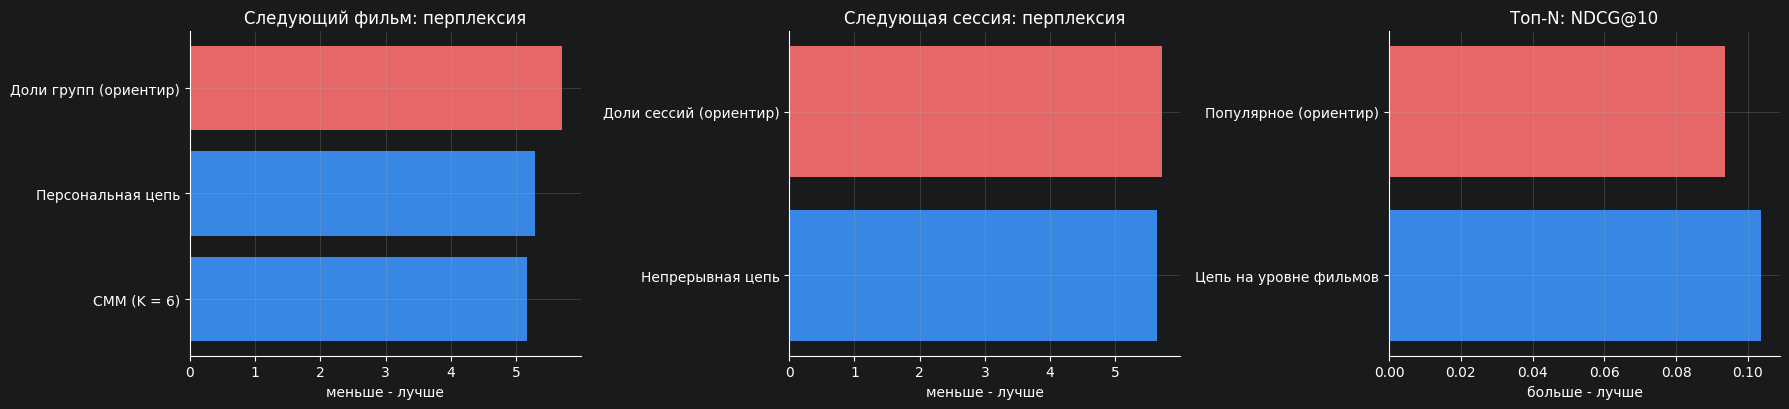

In [146]:
summary_sessions = pd.DataFrame(session_results).set_index("Модель")
summary_topn = topn_table()

print("1. Прогноз группы следующего фильма:")
print(next_table.round(4).to_string())
print("\n2. Прогноз группы следующей сессии:")
print(summary_sessions.round(4).to_string())
print("\n3. Топ-N рекомендации:")
print(summary_topn.round(4).to_string())

summary_topn.round(4).to_csv("work2_results.csv")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
for ax, (table, column, title) in zip(axes, [(next_table, "Перплексия", "Следующий фильм: перплексия"),
                                             (summary_sessions, "Перплексия", "Следующая сессия: перплексия"),
                                             (summary_topn, "NDCG@10", "Топ-N: NDCG@10")]):
    y = np.arange(len(table))
    ax.barh(y, table[column], color=[PALETTE[7] if "ориентир" in name else MAIN_COLOR for name in table.index])
    ax.set_yticks(y)
    ax.set_yticklabels(table.index)
    ax.invert_yaxis()
    ax.set_title(title)
axes[0].set_xlabel("меньше - лучше")
axes[1].set_xlabel("меньше - лучше")
axes[2].set_xlabel("больше - лучше")
plt.tight_layout()
plt.show()

Параметры моделей сохраняются в файл, чтобы скрипт проверки на новом пользователе использовал ровно те же матрицы.

In [147]:
np.savez(mc.DATA_DIR / "work2_models.npz",
         states=np.array(STATES), P_ratings=P_ratings, Q=Q, pi0=pi0, pi_ratings=pi_ratings, beta=BETA,
         item_window=ITEM_WINDOW, item_recent=ITEM_RECENT, item_alpha=ITEM_ALPHA,
         hmm_pi=hmm_full["pi"], hmm_A=hmm_full["A"], hmm_B=hmm_full["B"], hmm_names=np.array(hidden_names))
print("Сохранено:", mc.DATA_DIR / "work2_models.npz")

Сохранено: data\work2_models.npz


# Граф модели

Граф дискретной цепи по оценкам построен отдельно и приложен к отчёту. Вершины графа — 6 состояний в том же порядке и с теми же названиями, что в программе (`STATES`, индексы 0–5), дуги — переходы с вероятностями из матрицы `P_ratings`: петли для всех состояний и переходы между разными состояниями с вероятностью не меньше `GRAPH_THRESHOLD` (таблица `edge_table` в разделе «Свойства цепи»).

# Проверка на новом пользователе

Чтобы проверить **обобщающую способность** модели, используется скрипт `work2_markov.py`. Новый зритель, которого нет в данных, вводит последовательность фильмов, которые он посмотрел (в порядке просмотра), и сколько дней назад был последний просмотр. Скрипт выводит:
- текущее состояние и распределение группы на шагах $n = 1, 2, 3, 5, 10$ (персональная дискретная цепь, личная матрица строится по введённой последовательности);
- распределение группы в моменты времени после последнего просмотра (непрерывная цепь);
- скрытые режимы зрителя по алгоритму Витерби и вероятность его последовательности по СММ;
- 10 рекомендованных фильмов по цепи на уровне фильмов с пояснением, после каких из введённых фильмов их чаще всего смотрят.

```
python work2_markov.py           # интерактивный ввод
python work2_markov.py --demo    # готовый пример
```

Модельный метод здесь удобен: для нового зрителя не нужно ничего обучать заново — достаточно применить готовые матрицы к его последовательности.

# Выводы

**Предметная область и данные.** Для онлайн-кинотеатра построены модели последовательного выбора фильмов по оценкам 1 988 зрителей MovieLens за 2019–2023 годы (140 тыс. оценок в обучающей выборке). Состояния цепи — 6 жанровых групп: Семейное, Фантастика, Боевик, Триллер, Комедия, Драма. Самая крупная группа — «Фантастика» (35 % оценок): в неё попадают современные блокбастеры.

**Дискретная цепь.**
- Матрица переходных вероятностей оценена по 138 тыс. переходов, каждая клетка — не менее чем по 1 216 случаям. Цепь **регулярна**: все переходы возможны за один шаг, существует единственное стационарное распределение, и оно совпадает с долями групп в данных.
- Цепь быстро «забывает» начальное состояние: $|\lambda_2| = 0.24$, уже через 3 шага распределение отличается от стационарного меньше чем на 1 %. Знание текущей группы полезно только на ближайшие 1–2 фильма.
- Зрители склонны оставаться в группе: вероятность продолжить ту же группу в 1.3–2.5 раза выше её доли (сильнее всего у «Семейного» — 2.5 раза). Связь текущей и следующей группы статистически значима, но слабая (V Крамера = 0.14). Часть этой «липкости» объясняется не вкусом, а тем, что в одном заходе на сайт зрители оценивают фильмы из одной подборки.

**Непрерывная цепь.**
- Матрица интенсивностей оценена методом максимального правдоподобия по наблюдениям в моменты сессий. Цепь перемешивается очень быстро: среднее время пребывания в группе — от нескольких минут до часа с небольшим, и уже через несколько часов после сессии распределение группы практически стационарное.
- Это согласуется с данными: доля сессий той же группы почти не зависит от паузы (от 0.34 при паузе в несколько часов до 0.25–0.28 при паузе в недели и месяцы). Время с прошлого захода несёт мало информации о том, какую группу зритель выберет, — главное определяется его устойчивым личным вкусом, который общая для всех цепь не описывает.
- В прогнозе группы следующей сессии непрерывная цепь лишь немного лучше ориентира (перплексия 5.65 против 5.71).

**Применение для рекомендаций.**
- Прогноз группы следующего фильма: персональная цепь снижает перплексию с 5.70 (доли групп) до 5.28, точность растёт с 28.6 % до 31.3 %.
- Топ-N рекомендации: для них лучше всего подошла цепь, в которой каждый фильм — отдельное состояние. Она превосходит рекомендации популярного (NDCG@10 0.104 против 0.094) и рекомендует втрое разнообразнее (покрытие каталога 14.7 % против 4.5 %), но уступает анамнестическим методам работы №1 (NDCG@10 0.121). Причина — в данных: порядок оценок в MovieLens во многом отражает то, в каком порядке сайт показывал фильмы, а не порядок просмотра (внутри сессии зрители заметно чаще остаются в той же группе, чем между сессиями), поэтому последовательная модель получает мало информации сверх того, что уже знают методы работы №1.

**Скрытая Марковская модель** (дополнительное задание).
- Реализованы прямой-обратный алгоритм, алгоритм Витерби и алгоритм Баума — Велша; корректность проверена полным перебором на игрушечном примере.
- Модель с 6 скрытыми режимами — **лучшая модель прогноза группы следующего фильма** (перплексия 5.17, точность 32.6 %): скрытые режимы описывают поведение зрителя точнее, чем текущая группа.
- Режимы делятся на два типа: короткие (2–3 фильма подряд, «эпизоды» внутри сессии) и длительные (13–33 фильма), которые по сути описывают устойчивый вкус зрителя.
- Оценка модели подтверждает, что порядок просмотра несёт информацию, но небольшую: реальные последовательности для модели вероятнее перемешанных примерно на 4 % в расчёте на один фильм.

**Итог.** Марковские цепи дают компактную интерпретируемую модель поведения зрителей: матрицу переходов можно изобразить графом, а свойства цепи — время перемешивания, стационарное распределение — объясняют, насколько надолго текущий интерес зрителя определяет его выбор. На данных MovieLens этот «текущий интерес» живёт недолго (1–2 фильма, несколько часов), поэтому как самостоятельный рекомендательный метод цепи уступают коллаборативным методам работы №1. Их естественное применение — дополнять основной метод, повышая в выдаче фильмы той группы, которую зритель смотрит прямо сейчас.